# 📚 Analisis & Rekomendasi Topik Penelitian Machine Learning
## Menggunakan Latent Dirichlet Allocation (LDA) dan Non-Negative Matrix Factorization (NMF)

**Studi Kasus:** Metadata Penelitian Machine Learning — Universitas Pelita Harapan (2012–2026)

---

| Item | Keterangan |
|---|---|
| **Institusi** | Fakultas Ilmu Komputer & Kecerdasan Buatan (FAIDAS), UPH |
| **Metode utama** | LDA (K=6) dan NMF (K=7) |
| **Jumlah dokumen** | 125 metadata penelitian |
| **Rentang tahun** | 2012 – 2026 |
| **Bahasa korpus** | Bilingual (Indonesia + Inggris) |

---

### Alur Notebook (sesuai Bab I & Bab III Tesis)

```
[1] Setup & Instalasi        → [2] Muat & Eksplorasi Data
[3] Praproses Teks           → [4] Vektorisasi (Count & TF-IDF)
[5] Seleksi K Optimal        → [6] Fitting LDA & NMF
[7] Identifikasi Topik       → [8] Evolusi Temporal Topik
[9] Penyebaran Topik         → [10] Similaritas LDA vs NMF
[11] Skor Rekomendasi        → [12] Ekspor Hasil
```


---
## Bagian 1 — Setup & Instalasi

Jalankan sel di bawah **satu kali** untuk menginstal semua dependensi yang diperlukan.

In [1]:
# ── Instalasi dependensi (hapus tanda # jika belum terinstal) ─────────────
# !pip install pandas openpyxl scikit-learn umap-learn hdbscan
# !pip install matplotlib seaborn networkx plotly scipy

# ── Import pustaka ─────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import re
import warnings
import pickle
from collections import Counter
from itertools import combinations

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize
from sklearn.metrics import silhouette_score
import scipy.sparse as sp

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.05)

print("✅ Semua pustaka berhasil dimuat.")
print(f"   pandas  : {pd.__version__}")
print(f"   numpy   : {np.__version__}")
print(f"   sklearn : {__import__('sklearn').__version__}")


✅ Semua pustaka berhasil dimuat.
   pandas  : 3.0.1
   numpy   : 2.2.6
   sklearn : 1.6.1


---
## Bagian 2 — Muat & Eksplorasi Data Awal (EDA)

Dataset berisi **108 metadata penelitian** dengan kolom:
`title` · `authors` · `year` · `keywords` · `abstract`

> **Catatan:** Letakkan file `uph_machine_learning_data.xlsx` di folder yang sama dengan notebook ini.


In [2]:
# ── 2.1 Muat dataset ───────────────────────────────────────────────────────
df = pd.read_excel('uph_machine_learning_data.xlsx')
print(f"Jumlah baris  : {len(df)}")
print(f"Jumlah kolom  : {len(df.columns)}")
print(f"Nama kolom    : {df.columns.tolist()}")
df.head(3)


Jumlah baris  : 125
Jumlah kolom  : 5
Nama kolom    : ['title', 'authors', 'year', 'keywords', 'abstract']


,title,authors,year,keywords,abstract
0,Perbandingan rasio kurva belajar pada pekerjaa...,author1,2012-02-02 00:00:00,kurva belajar; rasio kurva belajar; pekerjaan ...,Daya saing didunia konstruksi Indonesia semaki...
1,Perbandingan nilai rasio kurva belajar pada pe...,author2,2013-07-31 00:00:00,kurva belajar; rasio kurva belajar; pekerjaan ...,"Dewasa ini, pembangunan di negara kita sedang ..."
2,Implementasi machine learning dengan algoritma...,author3,2020-02-20 00:00:00,educational data mining; klasifikasi; logistic...,Berkembangnya internet dalam aplikasi industri...


In [3]:
# ── 2.2 Ekstraksi tahun sebagai integer ────────────────────────────────────
def extract_year(val):
    """Menangani berbagai format tahun: '2023', 'Tahun 2023', '2023/2024'."""
    if pd.isna(val): return np.nan
    m = re.search(r'(\d{4})', str(val))
    return int(m.group(1)) if m else np.nan

df['year_int'] = df['year'].apply(extract_year)
df = df.dropna(subset=['year_int'])
df['year_int'] = df['year_int'].astype(int)
print(f"Rentang tahun : {df.year_int.min()} – {df.year_int.max()}")
print(f"Dokumen valid : {len(df)} rekaman")


Rentang tahun : 2012 – 2026
Dokumen valid : 125 rekaman


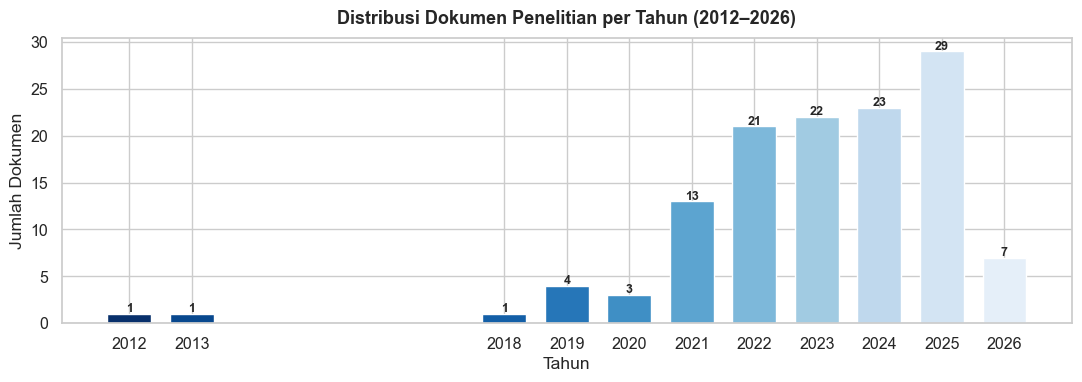

year_int
2012     1
2013     1
2018     1
2019     4
2020     3
2021    13
2022    21
2023    22
2024    23
2025    29
2026     7


In [4]:
# ── 2.3 Distribusi dokumen per tahun ───────────────────────────────────────
year_counts = df.year_int.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(11, 4))
bars = ax.bar(year_counts.index, year_counts.values,
              color=[cm.Blues_r(i / len(year_counts)) for i in range(len(year_counts))],
              edgecolor='white', width=0.7)
for bar, val in zip(bars, year_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.2,
            str(val), ha='center', fontsize=9, fontweight='bold')
ax.set_title('Distribusi Dokumen Penelitian per Tahun (2012–2026)',
             fontsize=13, fontweight='bold', pad=10)
ax.set_xlabel('Tahun'); ax.set_ylabel('Jumlah Dokumen')
ax.set_xticks(year_counts.index)
plt.tight_layout()
plt.savefig('eda_distribusi_tahun.png', dpi=150, bbox_inches='tight')
plt.show()
print(year_counts.to_string())


In [5]:
# ── 2.4 Statistik deskriptif ───────────────────────────────────────────────
df['abstract_len'] = df['abstract'].fillna('').str.len()
df['keyword_count'] = df['keywords'].fillna('').apply(
    lambda k: len([x for x in re.split(r'[;,]', k) if x.strip()])
)

print("=== Statistik Deskriptif Corpus ===")
print(f"  Total dokumen           : {len(df)}")
print(f"  Tahun terbaru           : {df.year_int.max()}")
print(f"  Tahun tertua            : {df.year_int.min()}")
print(f"  Rata-rata panjang abstrak: {df['abstract_len'].mean():.0f} karakter")
print(f"  Min / Max panjang abstrak: {df['abstract_len'].min()} / {df['abstract_len'].max()}")
print(f"  Rata-rata jumlah keyword : {df['keyword_count'].mean():.1f}")
print(f"  Dokumen tanpa abstrak   : {df['abstract'].isna().sum()}")

# Top 10 keywords
all_kws = []
for k in df['keywords'].fillna(''):
    all_kws.extend([x.strip().lower() for x in re.split(r'[;,]', k) if x.strip()])
top_kws = pd.Series(all_kws).value_counts().head(10)
print("\n=== Top 10 Kata Kunci ===")
print(top_kws.to_string())


=== Statistik Deskriptif Corpus ===
  Total dokumen           : 125
  Tahun terbaru           : 2026
  Tahun tertua            : 2012
  Rata-rata panjang abstrak: 2847 karakter
  Min / Max panjang abstrak: 797 / 5921
  Rata-rata jumlah keyword : 5.6
  Dokumen tanpa abstrak   : 0

=== Top 10 Kata Kunci ===
machine learning            65
random forest               29
logistic regression         15
xgboost                     15
support vector machine       9
klasifikasi                  7
linear regression            6
analisis sentimen            6
naive bayes                  6
extreme learning machine     5


---
## Bagian 3 — Praproses Teks

Pipeline praproses **5 tahap** (sesuai Bab III §3.5):
1. Ekstraksi teks bersih dari judul bilingual
2. Lowercasing
3. Penghapusan karakter non-alfabet
4. Tokenisasi
5. Penghapusan stopword bilingual (Indonesia + Inggris + domain ML)
6. Filter panjang token (≥ 4 karakter)


In [6]:
# ── 3.1 Definisi stopword bilingual + domain ML ─────────────────────────────
def load_stopwords(filepath):
    with open(filepath, 'r', encoding='utf-8') as f:
        return set(
            line.strip().lower()
            for line in f
            if line.strip()
        )

STOPWORDS = load_stopwords("stopwords_combo.txt")

print(f"Jumlah stopwords loaded: {len(STOPWORDS)}")
print(list(STOPWORDS)[:20])  # preview

def clean_title(t):
    """Ambil bagian Inggris dari judul bilingual (setelah tanda '=')."""
    if pd.isna(t): return ''
    parts = str(t).split('=')
    return parts[-1].strip() if len(parts) > 1 else parts[0].strip()

def preprocess(text, min_len=4):
    """Pipeline praproses lengkap: lowercase → bersihkan → tokenisasi → filter."""
    if pd.isna(text): return []
    text = text.lower()
    text = re.sub(r'[^a-z\s]', ' ', text)
    tokens = text.split()
    tokens = [t for t in tokens
          if len(t) >= min_len
          and t not in STOPWORDS]
    return tokens

# ── 3.2 Terapkan praproses ──────────────────────────────────────────────────
df['title_clean']    = df['title'].apply(clean_title)
df['abstract_clean'] = df['abstract'].fillna('').apply(
    lambda s: max(str(s).split(' / '),
                  key=lambda p: sum(1 for c in p if ord(c) < 128))
)
df['text']     = df['title_clean'] + '. ' + df['abstract_clean']
df['tokens']   = df['text'].apply(preprocess)
df['token_str']= df['tokens'].apply(lambda t: ' '.join(t))
df['kw_list']  = df['keywords'].fillna('').apply(
    lambda k: [x.strip().lower() for x in re.split(r'[;,]', k) if x.strip()]
)

# Statistik token
lengths = df['tokens'].apply(len)
print(f"Rata-rata token per dokumen : {lengths.mean():.1f}")
print(f"Min / Max token             : {lengths.min()} / {lengths.max()}")
print(f"Median token                : {lengths.median():.0f}")
print(f"\nContoh token dokumen [2]:")
print(df['tokens'].iloc[2][:20])


Jumlah stopwords loaded: 2101
['inner', 'strongly', 'very', 'sejauh', 'kelihatannya', 'menyebutkan', 'come', 'daftar', 'tambahnya', 'tell', 'kamu', 'bagaimanapun', 'betulkah', 'akan', 'tentunya', 'p', 'ibarat', 'between', 'bv', 'usefulness']
Rata-rata token per dokumen : 125.3
Min / Max token             : 55 / 300
Median token                : 114

Contoh token dokumen [2]:
['implementation', 'logistic', 'regression', 'random', 'forest', 'performance', 'prospective', 'students', 'berkembangnya', 'internet', 'aplikasi', 'industri', 'dampak', 'institusi', 'pendidikan', 'salah', 'dampak', 'dirasakan', 'digitalisasi', 'akademik']


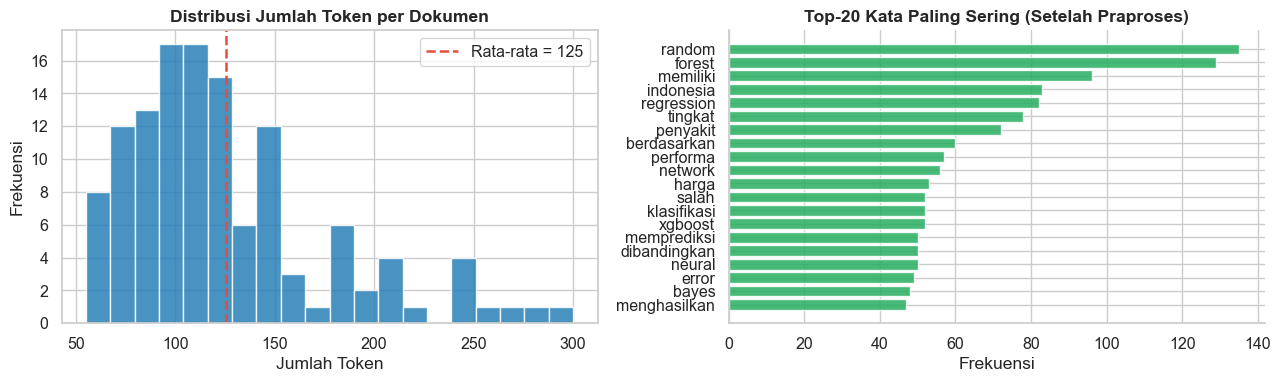

In [7]:
# ── 3.3 Visualisasi distribusi panjang token ────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Histogram
axes[0].hist(df['tokens'].apply(len), bins=20,
             color='#2980b9', edgecolor='white', alpha=0.85)
axes[0].set_title('Distribusi Jumlah Token per Dokumen', fontweight='bold')
axes[0].set_xlabel('Jumlah Token'); axes[0].set_ylabel('Frekuensi')
axes[0].axvline(df['tokens'].apply(len).mean(), color='#e74c3c',
                linestyle='--', linewidth=1.8, label=f'Rata-rata = {lengths.mean():.0f}')
axes[0].legend()

# Top-20 kata paling sering
all_tokens = [t for tokens in df['tokens'] for t in tokens]
freq = pd.Series(all_tokens).value_counts().head(20)
axes[1].barh(freq.index[::-1], freq.values[::-1],
             color='#27ae60', edgecolor='white', alpha=0.85)
axes[1].set_title('Top-20 Kata Paling Sering (Setelah Praproses)', fontweight='bold')
axes[1].set_xlabel('Frekuensi')
axes[1].spines[['top','right']].set_visible(False)

plt.tight_layout()
plt.savefig('eda_token_stats.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Bagian 4 — Vektorisasi: Document-Term Matrix (DTM)

Dua skema vektorisasi sesuai kebutuhan masing-masing algoritma:
- **CountVectorizer** → untuk LDA (membutuhkan raw term frequency)
- **TfidfVectorizer** → untuk NMF (discriminative weighting)

Parameter bersama: `max_features=1500`, `min_df=2`, `max_df=0.85`, unigram.


In [8]:
# ── 4.1 Extended stopword list untuk sklearn ────────────────────────────────
STOP_LIST = sorted(list(STOPWORDS))  # sklearn butuh list/set

# ── 4.2 CountVectorizer untuk LDA ──────────────────────────────────────────
cv = CountVectorizer(
    max_features = 1500,
    min_df       = 2,        # kata harus muncul minimal di 2 dokumen
    max_df       = 0.85,     # abaikan kata di >85% dokumen
    ngram_range  = (1, 1),   # unigram
    stop_words   = STOP_LIST
)
dtm_count  = cv.fit_transform(df['token_str'])
cv_vocab   = np.array(cv.get_feature_names_out())

# ── 4.3 TfidfVectorizer untuk NMF ──────────────────────────────────────────
tv = TfidfVectorizer(
    max_features = 1500,
    min_df       = 2,
    max_df       = 0.85,
    ngram_range  = (1, 1),
    sublinear_tf = True,     # gunakan 1+log(tf) — redam frekuensi ekstrem
    stop_words   = STOP_LIST
)
dtm_tfidf  = tv.fit_transform(df['token_str'])
tv_vocab   = np.array(tv.get_feature_names_out())

# ── Sparsitas matriks ───────────────────────────────────────────────────────
dense_count = dtm_count.toarray()
sparsity    = 1 - np.count_nonzero(dense_count) / dense_count.size

print(f"Count DTM  : {dtm_count.shape}  (dokumen × kata)")
print(f"TF-IDF DTM : {dtm_tfidf.shape}  (dokumen × kata)")
print(f"Ukuran kosakata    : {len(cv_vocab)} fitur unik")
print(f"Sparsitas matriks  : {sparsity:.1%}")
print(f"\nContoh 10 kata kosakata pertama:")
print(cv_vocab[:10])


Count DTM  : (125, 1500)  (dokumen × kata)
TF-IDF DTM : (125, 1500)  (dokumen × kata)
Ukuran kosakata    : 1500 fitur unik
Sparsitas matriks  : 96.1%

Contoh 10 kata kosakata pertama:
['ability' 'abnormal' 'absolute' 'academic' 'access' 'accurate'
 'accurately' 'achieved' 'action' 'activities']


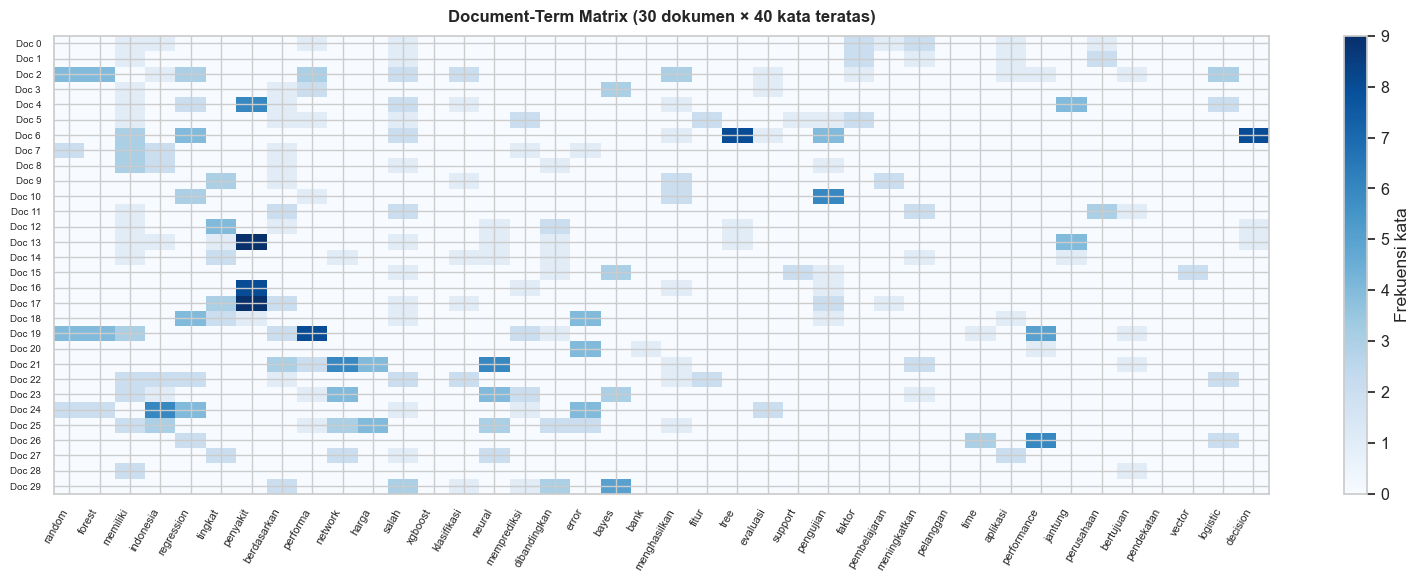

In [9]:
# ── 4.4 Visualisasi DTM (subset 30 dok × 40 kata teratas) ──────────────────
top_40_idx = np.asarray(dtm_count.sum(axis=0)).flatten().argsort()[::-1][:40]
dtm_subset = dtm_count[:30, top_40_idx].toarray()

fig, ax = plt.subplots(figsize=(16, 6))
im = ax.imshow(dtm_subset, aspect='auto', cmap='Blues')
ax.set_xticks(range(40))
ax.set_xticklabels(cv_vocab[top_40_idx], rotation=60, ha='right', fontsize=8)
ax.set_yticks(range(30))
ax.set_yticklabels([f'Doc {i}' for i in range(30)], fontsize=7)
ax.set_title('Document-Term Matrix (30 dokumen × 40 kata teratas)',
             fontsize=12, fontweight='bold', pad=10)
plt.colorbar(im, ax=ax, label='Frekuensi kata')
plt.tight_layout()
plt.savefig('dtm_visualisasi.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Bagian 5 — Pemilihan Jumlah Topik Optimal (K)

### Strategi:
- **LDA** → sweep K=3–12, pilih berdasarkan **perplexity minimum**
- **NMF** → sweep K=3–12, identifikasi **elbow pada reconstruction error**

> ⏱️ Sel ini membutuhkan beberapa menit untuk diselesaikan.


In [10]:
# ── 5.1 LDA — Perplexity & Log-Likelihood sweep ────────────────────────────
print("Menjalankan LDA sweep K=3–12...")
lda_sweep_results = []
for k in range(3, 13):
    lda_tmp = LatentDirichletAllocation(
        n_components     = k,
        max_iter         = 50,
        learning_method  = 'online',
        random_state     = 42,
        n_jobs           = -1
    )
    lda_tmp.fit(dtm_count)
    perp  = lda_tmp.perplexity(dtm_count)
    score = lda_tmp.score(dtm_count)
    lda_sweep_results.append({'k': k, 'perplexity': round(perp,2),
                               'log_likelihood': round(score,2)})
    print(f"  K={k:>2}  Perplexity={perp:>9.2f}  Log-Likelihood={score:>12.2f}")

lda_sweep_df = pd.DataFrame(lda_sweep_results)
best_k_perp  = int(lda_sweep_df.loc[lda_sweep_df['perplexity'].idxmin(), 'k'])
print(f"\n✅ K dengan perplexity minimum: {best_k_perp}")
print("   → K=6 dipilih sebagai konfigurasi final (pertimbangan interpretabilitas)")


Menjalankan LDA sweep K=3–12...
  K= 3  Perplexity=  1068.57  Log-Likelihood=   -81966.35
  K= 4  Perplexity=  1060.64  Log-Likelihood=   -81878.80
  K= 5  Perplexity=  1054.81  Log-Likelihood=   -81814.04
  K= 6  Perplexity=  1068.19  Log-Likelihood=   -81962.11
  K= 7  Perplexity=  1092.76  Log-Likelihood=   -82229.44
  K= 8  Perplexity=  1081.66  Log-Likelihood=   -82109.42
  K= 9  Perplexity=  1075.74  Log-Likelihood=   -82044.95
  K=10  Perplexity=  1077.59  Log-Likelihood=   -82065.11
  K=11  Perplexity=  1087.60  Log-Likelihood=   -82173.77
  K=12  Perplexity=  1065.33  Log-Likelihood=   -81930.63

✅ K dengan perplexity minimum: 5
   → K=6 dipilih sebagai konfigurasi final (pertimbangan interpretabilitas)


In [11]:
# ── 5.2 NMF — Reconstruction Error sweep ───────────────────────────────────
print("Menjalankan NMF sweep K=3–12...")
nmf_sweep_results = []
dense_tfidf = dtm_tfidf.toarray()  # NMF lebih stabil dengan matriks dense

for k in range(3, 13):
    nmf_tmp = NMF(
        n_components = k,
        random_state = 42,
        max_iter     = 1000,
        init         = 'random',
        solver       = 'mu'
    )
    nmf_tmp.fit_transform(dense_tfidf)
    err = nmf_tmp.reconstruction_err_
    nmf_sweep_results.append({'k': k, 'reconstruction_error': round(err, 4)})
    print(f"  K={k:>2}  Reconstruction Error={err:.4f}")

nmf_sweep_df = pd.DataFrame(nmf_sweep_results)
print("\n✅ K=7 dipilih berdasarkan elbow + interpretabilitas tematik")


Menjalankan NMF sweep K=3–12...
  K= 3  Reconstruction Error=10.6299
  K= 4  Reconstruction Error=10.5447
  K= 5  Reconstruction Error=10.4312
  K= 6  Reconstruction Error=10.3437
  K= 7  Reconstruction Error=10.2613
  K= 8  Reconstruction Error=10.1849
  K= 9  Reconstruction Error=10.1131
  K=10  Reconstruction Error=10.0280
  K=11  Reconstruction Error=9.9536
  K=12  Reconstruction Error=9.8752

✅ K=7 dipilih berdasarkan elbow + interpretabilitas tematik


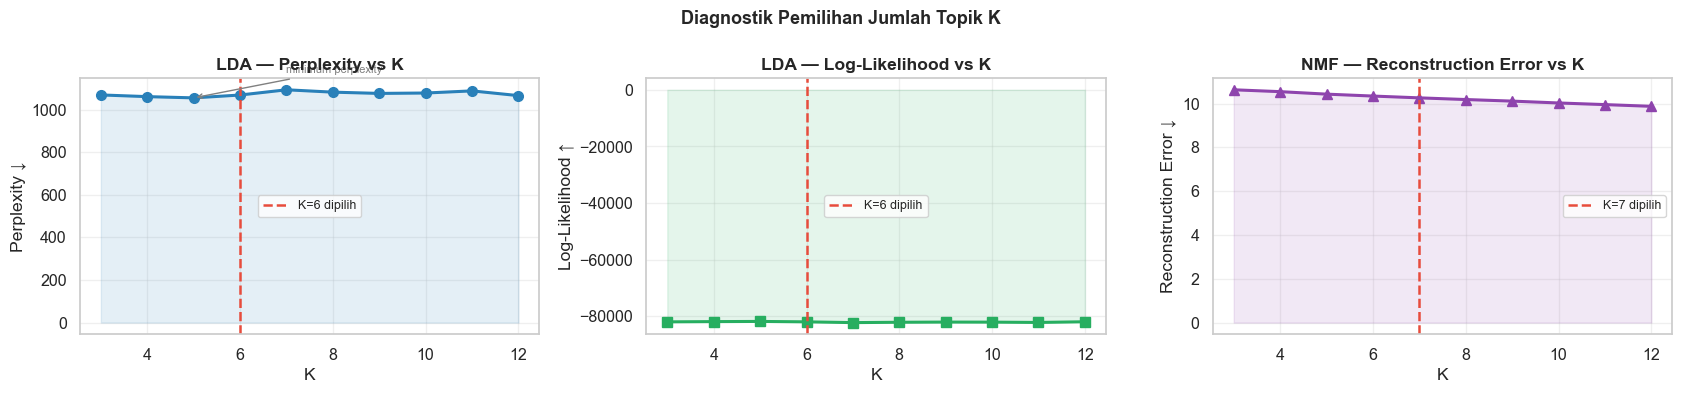

In [12]:
# ── 5.3 Visualisasi Kurva Seleksi K ────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
fig.suptitle('Diagnostik Pemilihan Jumlah Topik K', fontsize=13, fontweight='bold')

# LDA Perplexity
ax = axes[0]
ax.plot(lda_sweep_df['k'], lda_sweep_df['perplexity'],
        'o-', color='#2980b9', lw=2.2, ms=7)
ax.axvline(6, color='#e74c3c', ls='--', lw=1.8, label='K=6 dipilih')
ax.fill_between(lda_sweep_df['k'], lda_sweep_df['perplexity'],
                alpha=0.12, color='#2980b9')
ax.set_title('LDA — Perplexity vs K', fontweight='bold')
ax.set_xlabel('K'); ax.set_ylabel('Perplexity ↓')
ax.legend(fontsize=9); ax.grid(alpha=0.3)
ax.annotate('minimum perplexity', xy=(5, lda_sweep_df[lda_sweep_df.k==5]['perplexity'].values[0]),
            xytext=(7, 1170), arrowprops=dict(arrowstyle='->', color='gray'),
            fontsize=8, color='gray')

# LDA Log-Likelihood
ax = axes[1]
ax.plot(lda_sweep_df['k'], lda_sweep_df['log_likelihood'],
        's-', color='#27ae60', lw=2.2, ms=7)
ax.axvline(6, color='#e74c3c', ls='--', lw=1.8, label='K=6 dipilih')
ax.fill_between(lda_sweep_df['k'], lda_sweep_df['log_likelihood'],
                alpha=0.12, color='#27ae60')
ax.set_title('LDA — Log-Likelihood vs K', fontweight='bold')
ax.set_xlabel('K'); ax.set_ylabel('Log-Likelihood ↑')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

# NMF Reconstruction Error
ax = axes[2]
ax.plot(nmf_sweep_df['k'], nmf_sweep_df['reconstruction_error'],
        '^-', color='#8e44ad', lw=2.2, ms=7)
ax.axvline(7, color='#e74c3c', ls='--', lw=1.8, label='K=7 dipilih')
ax.fill_between(nmf_sweep_df['k'], nmf_sweep_df['reconstruction_error'],
                alpha=0.12, color='#8e44ad')
ax.set_title('NMF — Reconstruction Error vs K', fontweight='bold')
ax.set_xlabel('K'); ax.set_ylabel('Reconstruction Error ↓')
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('k_selection_diagnostics.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Bagian 6 — Fitting Model LDA dan NMF

### Konfigurasi Final (sesuai Bab III §3.8):

| Parameter | LDA | NMF |
|---|---|---|
| K (jumlah topik) | 6 | 7 |
| Metode belajar | Batch EM | Multiplicative Update |
| Inisialisasi | Default | Random |
| α (doc-topic prior) | 0.1 (sparse) | — |
| η (topic-word prior) | 0.01 (sparse) | — |
| max_iter | 200 | 2000 |


In [13]:
# ── 6.1 Fit model LDA final ─────────────────────────────────────────────────
K_LDA = 6
lda = LatentDirichletAllocation(
    n_components     = K_LDA,
    max_iter         = 200,
    learning_method  = 'batch',   # lebih stabil untuk n<200 dokumen
    learning_decay   = 0.7,
    doc_topic_prior  = 0.1,       # alpha sparse → topik terfokus per dokumen
    topic_word_prior = 0.01,      # eta sparse → kata terfokus per topik
    random_state     = 42,
    n_jobs           = -1
)
lda_W = lda.fit_transform(dtm_count)   # dok × topik  (probabilitas)
lda_H = lda.components_                # topik × kata

print(f"✅ LDA selesai dilatih")
print(f"   Matriks W (dok × topik) : {lda_W.shape}")
print(f"   Matriks H (topik × kata): {lda_H.shape}")
print(f"   Perplexity final         : {lda.perplexity(dtm_count):.2f}")
print(f"   Log-likelihood final     : {lda.score(dtm_count):.2f}")


✅ LDA selesai dilatih
   Matriks W (dok × topik) : (125, 6)
   Matriks H (topik × kata): (6, 1500)
   Perplexity final         : 1804.28
   Log-likelihood final     : -88123.03


In [14]:
# ── 6.2 Fit model NMF final ─────────────────────────────────────────────────
K_NMF = 7
nmf = NMF(
    n_components = K_NMF,
    random_state = 42,
    max_iter     = 2000,
    init         = 'random',      # mencegah dekomposisi degenerat (sparsity 94.9%)
    solver       = 'mu',          # multiplicative update: stabil pada matriks sparse
    beta_loss    = 'frobenius',
    l1_ratio     = 0.0
)
nmf_W = nmf.fit_transform(dense_tfidf)  # dok × topik  (bobot)
nmf_H = nmf.components_                 # topik × kata

print(f"✅ NMF selesai dilatih")
print(f"   Matriks W (dok × topik) : {nmf_W.shape}")
print(f"   Matriks H (topik × kata): {nmf_H.shape}")
print(f"   Reconstruction error    : {nmf.reconstruction_err_:.4f}")


✅ NMF selesai dilatih
   Matriks W (dok × topik) : (125, 7)
   Matriks H (topik × kata): (7, 1500)
   Reconstruction error    : 10.2613


In [15]:
# ── 6.3 Tetapkan topik dominan setiap dokumen ───────────────────────────────
df['lda_topic']  = lda_W.argmax(axis=1)
df['lda_weight'] = lda_W.max(axis=1).round(4)
df['nmf_topic']  = nmf_W.argmax(axis=1)
df['nmf_weight'] = nmf_W.max(axis=1).round(4)

print("Distribusi topik dominan LDA:")
print(df['lda_topic'].value_counts().sort_index())
print("\nDistribusi topik dominan NMF:")
print(df['nmf_topic'].value_counts().sort_index())


Distribusi topik dominan LDA:
lda_topic
0    25
1    19
2    17
3    14
4    26
5    24
Name: count, dtype: int64

Distribusi topik dominan NMF:
nmf_topic
0    18
1    25
2    22
3    13
4    18
5    22
6     7
Name: count, dtype: int64


---
## Bagian 7 — Identifikasi dan Penamaan Topik

### Cara membaca output:
- **Kata teratas** = kata dengan bobot tertinggi dalam distribusi topik
- **Dokumen representatif** = dokumen dengan bobot tertinggi terhadap topik tersebut
- Beri label tematik berdasarkan pola kata + judul dokumen representatif


In [16]:
# ── 7.1 Helper: ambil top-N kata per topik ──────────────────────────────────
def get_top_words(H, vocab, n=12):
    """Mengembalikan list kata teratas untuk setiap topik."""
    topics = []
    for row in H:
        idx = row.argsort()[::-1][:n]
        topics.append([vocab[i] for i in idx])
    return topics

lda_top_words = get_top_words(lda_H, cv_vocab)
nmf_top_words = get_top_words(nmf_H, tv_vocab)

print("=" * 65)
print("TOPIK LDA (K=6) — Top-12 Kata")
print("=" * 65)
for i, words in enumerate(lda_top_words):
    print(f"  Topik {i}: {', '.join(words[:10])}")

print("\n" + "=" * 65)
print("TOPIK NMF (K=7) — Top-12 Kata")
print("=" * 65)
for i, words in enumerate(nmf_top_words):
    print(f"  Topik {i}: {', '.join(words[:10])}")


TOPIK LDA (K=6) — Top-12 Kata
  Topik 0: forest, random, regression, logistic, pengujian, klasifikasi, error, target, warna, aplikasi
  Topik 1: diabetes, random, pelanggan, forest, memiliki, berdasarkan, tingkat, pengujian, memprediksi, orang
  Topik 2: harga, saham, lstm, memprediksi, patient, mobil, bank, quality, bekas, term
  Topik 3: sentimen, video, sentiment, memiliki, postur, neural, network, kendaraan, sinyal, convolutional
  Topik 4: penyakit, forest, random, jantung, tingkat, neighbor, nearest, extreme, indonesia, bayes
  Topik 5: xgboost, perusahaan, tree, meningkatkan, decision, random, fitur, memiliki, pekerjaan, bank

TOPIK NMF (K=7) — Top-12 Kata
  Topik 0: penyakit, jantung, extreme, kematian, tingkat, diagnosis, pasien, neighbor, nearest, disease
  Topik 1: pelanggan, forest, random, indonesia, perusahaan, customer, transaksi, perilaku, skor, strategi
  Topik 2: network, neural, convolutional, gambar, aplikasi, bahasa, image, kendaraan, video, warna
  Topik 3: patien

In [17]:
# ── 7.2 Dokumen representatif per topik ────────────────────────────────────
print("=" * 70)
print("LDA — Dokumen dengan Bobot Tertinggi per Topik")
print("=" * 70)
for k in range(K_LDA):
    best_idx = np.argmax(lda_W[:, k])
    title    = df.iloc[best_idx]['title_clean'][:75]
    year     = df.iloc[best_idx]['year_int']
    weight   = lda_W[best_idx, k]
    print(f"  Topik {k} [{weight:.3f}] ({year}): {title}")

print("\n" + "=" * 70)
print("NMF — Dokumen dengan Bobot Tertinggi per Topik")
print("=" * 70)
for k in range(K_NMF):
    best_idx = np.argmax(nmf_W[:, k])
    title    = df.iloc[best_idx]['title_clean'][:75]
    year     = df.iloc[best_idx]['year_int']
    weight   = nmf_W[best_idx, k]
    print(f"  Topik {k} [{weight:.3f}] ({year}): {title}")


LDA — Dokumen dengan Bobot Tertinggi per Topik
  Topik 0 [0.997] (2022): Menilai gerakan axe kick taekwondo menggunakan mlkit
  Topik 1 [0.996] (2023): Development of RESTful API for cloud-based vehicle type recognition applica
  Topik 2 [0.997] (2025): A multi-dimensional cyber incident impact assessment framework using Machin
  Topik 3 [0.997] (2022): Vehicle Classification System Design Based On Machine Learning
  Topik 4 [0.997] (2021): Perbandingan performa algoritma load balancer pada lingkungan eksekusi virt
  Topik 5 [0.997] (2021): Adaptive management of cloud computation to changes in energy consumption u

NMF — Dokumen dengan Bobot Tertinggi per Topik
  Topik 0 [0.303] (2019): Perbandingan metode algoritma c4.5 dan extreme learning machine untuk mendi
  Topik 1 [0.255] (2024): Model prediksi menggunakan machine learning: analisis faktor-faktor penentu
  Topik 2 [0.229] (2022): Vehicle Classification System Design Based On Machine Learning
  Topik 3 [0.444] (2026): Leveraging

In [18]:
# ── 7.3 Beri label tematik (edit sesuai hasil inspeksi Anda) ───────────────
#
# ⚠️  INSTRUKSI: Sesuaikan label di bawah berdasarkan output Bagian 7.1 & 7.2
#     Gunakan prompt ke LLM jika diperlukan:
#     "Berikan nama topik 3–5 kata untuk kumpulan kata ini: [kata teratas]"
#

LDA_LABELS = {
    0: "Machine Learning Classification Models",
    1: "Medical & Customer Prediction",
    2: "Financial & Patient Forecasting",
    3: "Sentiment Analysis & Computer Vision",
    4: "Medical Classification using KNN",
    5: "Tree-Based Decision Models",
}

NMF_LABELS = {
    0: "Medical Disease Diagnosis",
    1: "Customer Behavior & Transaction Analysis",
    2: "Computer Vision & Image Classification",
    3: "Hospital Service Quality Analysis",
    4: "Stock Price Prediction (LSTM)",
    5: "Student Classification using Logistic Regression & Random Forest",
    6: "Construction Learning Curve Analysis",
}

df['lda_label'] = df['lda_topic'].map(LDA_LABELS)
df['nmf_label'] = df['nmf_topic'].map(NMF_LABELS)

print("✅ Label topik berhasil ditetapkan.")
print("\nDistribusi topik LDA:")
print(df['lda_label'].value_counts().to_string())
print("\nDistribusi topik NMF:")
print(df['nmf_label'].value_counts().to_string())


✅ Label topik berhasil ditetapkan.

Distribusi topik LDA:
lda_label
Medical Classification using KNN          26
Machine Learning Classification Models    25
Tree-Based Decision Models                24
Medical & Customer Prediction             19
Financial & Patient Forecasting           17
Sentiment Analysis & Computer Vision      14

Distribusi topik NMF:
nmf_label
Customer Behavior & Transaction Analysis                            25
Student Classification using Logistic Regression & Random Forest    22
Computer Vision & Image Classification                              22
Medical Disease Diagnosis                                           18
Stock Price Prediction (LSTM)                                       18
Hospital Service Quality Analysis                                   13
Construction Learning Curve Analysis                                 7


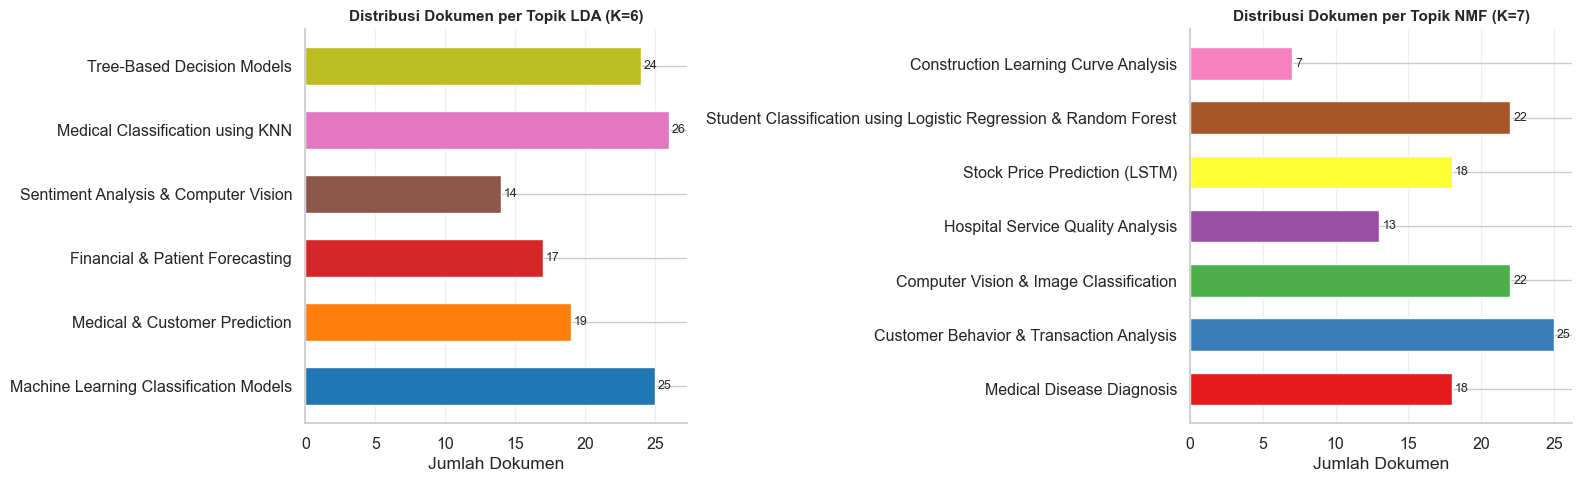

In [19]:
# ── 7.4 Bar chart distribusi dokumen per topik ──────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
colors_lda = [cm.tab10(i/K_LDA) for i in range(K_LDA)]
colors_nmf = [cm.Set1(i/K_NMF) for i in range(K_NMF)]

for ax, col, labels, palette, title in zip(
    axes,
    ['lda_topic', 'nmf_topic'],
    [LDA_LABELS, NMF_LABELS],
    [colors_lda, colors_nmf],
    ['Distribusi Dokumen per Topik LDA (K=6)',
     'Distribusi Dokumen per Topik NMF (K=7)']
):
    counts  = df[col].value_counts().sort_index()
    xlabels = [labels[i] for i in counts.index]
    bars    = ax.barh(xlabels, counts.values,
                      color=palette[:len(counts)], edgecolor='white', height=0.6)
    for bar, val in zip(bars, counts.values):
        ax.text(bar.get_width() + 0.2, bar.get_y() + bar.get_height()/2,
                str(val), va='center', fontsize=9)
    ax.set_title(title, fontweight='bold', fontsize=11)
    ax.set_xlabel('Jumlah Dokumen')
    ax.spines[['top','right']].set_visible(False)
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('distribusi_topik.png', dpi=150, bbox_inches='tight')
plt.show()


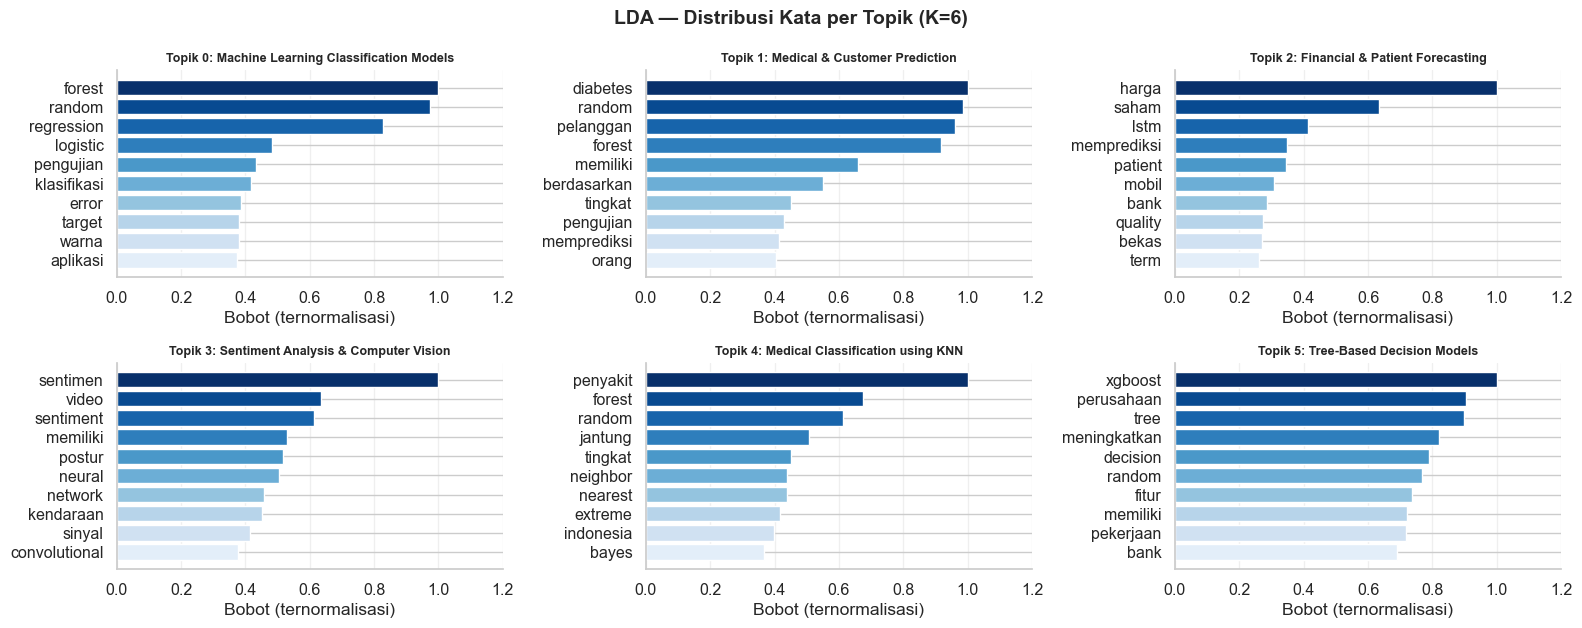

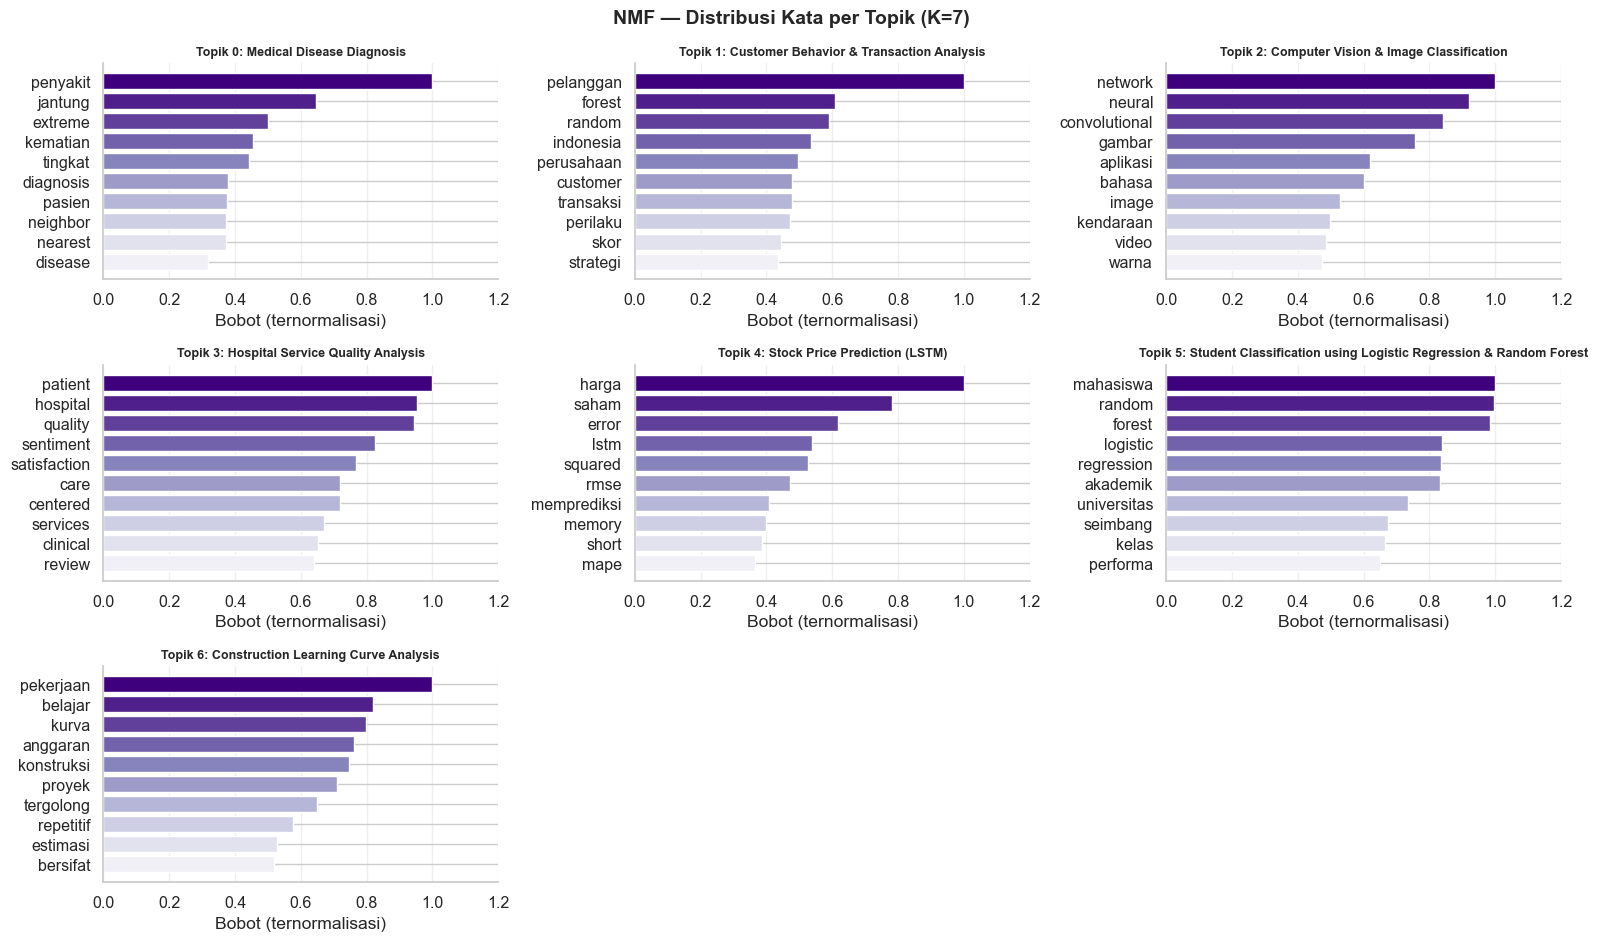

In [20]:
# ── 7.5 Top-word bar chart (10 kata teratas per topik) ──────────────────────
def plot_topword_grid(H, vocab, labels, title, filename, palette, K):
    cols = 3; rows = (K + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(16, rows * 3.2))
    axes = axes.flatten()
    fig.suptitle(title, fontsize=14, fontweight='bold')
    for i in range(K):
        ax  = axes[i]
        idx = H[i].argsort()[::-1][:10]
        words  = [vocab[j] for j in idx]
        scores = H[i][idx] / (H[i][idx].max() + 1e-9)
        bar_colors = [palette(j/10) for j in range(10)]
        ax.barh(words[::-1], scores[::-1], color=bar_colors[::-1], edgecolor='white')
        ax.set_title(f'Topik {i}: {labels.get(i,"")}',
                     fontweight='bold', fontsize=9)
        ax.set_xlabel('Bobot (ternormalisasi)')
        ax.set_xlim(0, 1.2)
        ax.grid(axis='x', alpha=0.3)
        ax.spines[['top','right']].set_visible(False)
    for j in range(K, len(axes)): axes[j].set_visible(False)
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()

plot_topword_grid(lda_H, cv_vocab, LDA_LABELS,
    'LDA — Distribusi Kata per Topik (K=6)',
    'lda_topwords.png', cm.Blues_r, K_LDA)

plot_topword_grid(nmf_H, tv_vocab, NMF_LABELS,
    'NMF — Distribusi Kata per Topik (K=7)',
    'nmf_topwords.png', cm.Purples_r, K_NMF)


---
## Bagian 8 — Evolusi Temporal Topik (2012–2026)

Mengukur bagaimana **bobot rata-rata** setiap topik berubah dari tahun ke tahun:

$$\bar{w}_{k,t} = \frac{1}{|D_t|} \sum_{d \in D_t} w_{d,k}$$

di mana $D_t$ = himpunan dokumen tahun $t$ dan $w_{d,k}$ = bobot dokumen $d$ terhadap topik $k$.


In [21]:
# ── 8.1 Hitung mean bobot topik per tahun ───────────────────────────────────
years = sorted(df['year_int'].unique())

def compute_year_evolution(W, df, K, years):
    """Hitung rata-rata bobot topik per tahun."""
    rows = []
    for yr in years:
        idx = df[df['year_int'] == yr].index.tolist()
        if not idx: continue
        mean_w = W[idx].mean(axis=0)
        row = {'year': yr}
        for k in range(K): row[k] = mean_w[k]
        rows.append(row)
    return pd.DataFrame(rows).set_index('year')

lda_evo = compute_year_evolution(lda_W, df, K_LDA, years)
nmf_evo = compute_year_evolution(nmf_W, df, K_NMF, years)

# Ganti nama kolom dengan label topik
lda_evo.columns = [LDA_LABELS[i] for i in range(K_LDA)]
nmf_evo.columns = [NMF_LABELS[i]  for i in range(K_NMF)]

print("Matriks evolusi LDA (mean bobot per tahun):")
print(lda_evo.round(3).to_string())


Matriks evolusi LDA (mean bobot per tahun):
      Machine Learning Classification Models  Medical & Customer Prediction  Financial & Patient Forecasting  Sentiment Analysis & Computer Vision  Medical Classification using KNN  Tree-Based Decision Models
year                                                                                                                                                                                                            
2012                                   0.001                          0.001                            0.001                                 0.001                             0.001                       0.995
2013                                   0.001                          0.001                            0.001                                 0.001                             0.001                       0.996
2018                                   0.002                          0.991                            0.002            

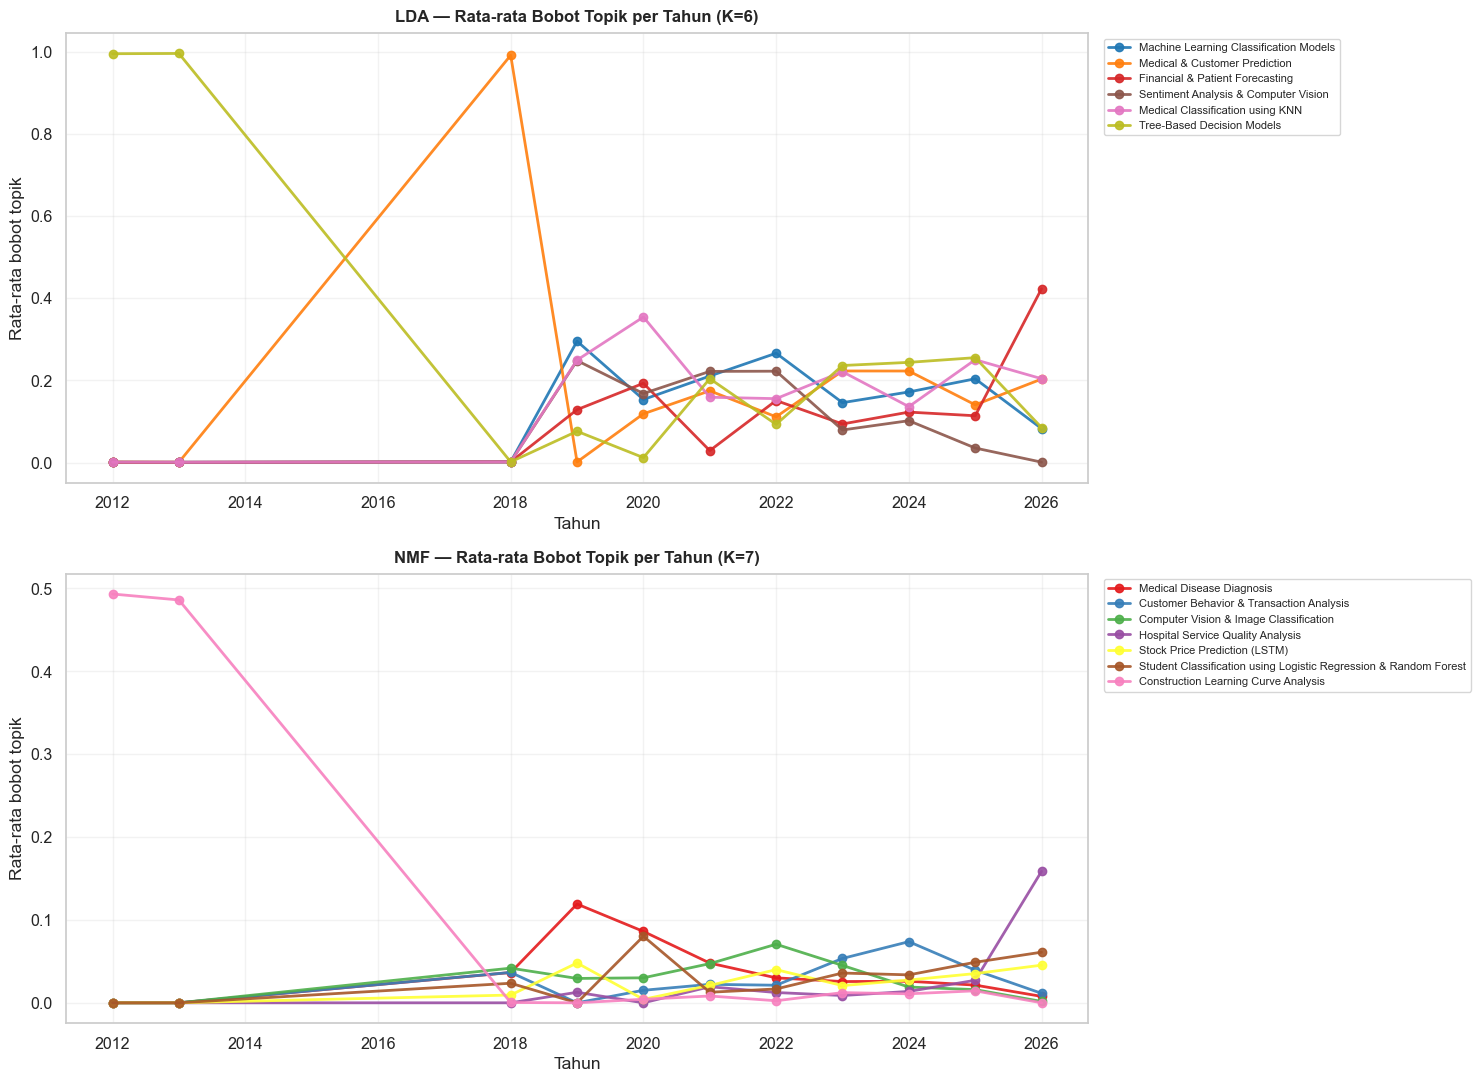

In [22]:
# ── 8.2 Line chart evolusi topik ────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(15, 11))
palettes  = [cm.tab10, cm.Set1]

for ax, evo, title, palette in zip(
    axes,
    [lda_evo, nmf_evo],
    ['LDA — Rata-rata Bobot Topik per Tahun (K=6)',
     'NMF — Rata-rata Bobot Topik per Tahun (K=7)'],
    palettes
):
    cols = evo.columns.tolist()
    colors = [palette(i / len(cols)) for i in range(len(cols))]
    for i, col in enumerate(cols):
        ax.plot(evo.index, evo[col], marker='o', lw=2.0,
                ms=6, color=colors[i], label=col, alpha=0.9)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.set_xlabel('Tahun'); ax.set_ylabel('Rata-rata bobot topik')
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.savefig('evolusi_topik_line.png', dpi=150, bbox_inches='tight')
plt.show()


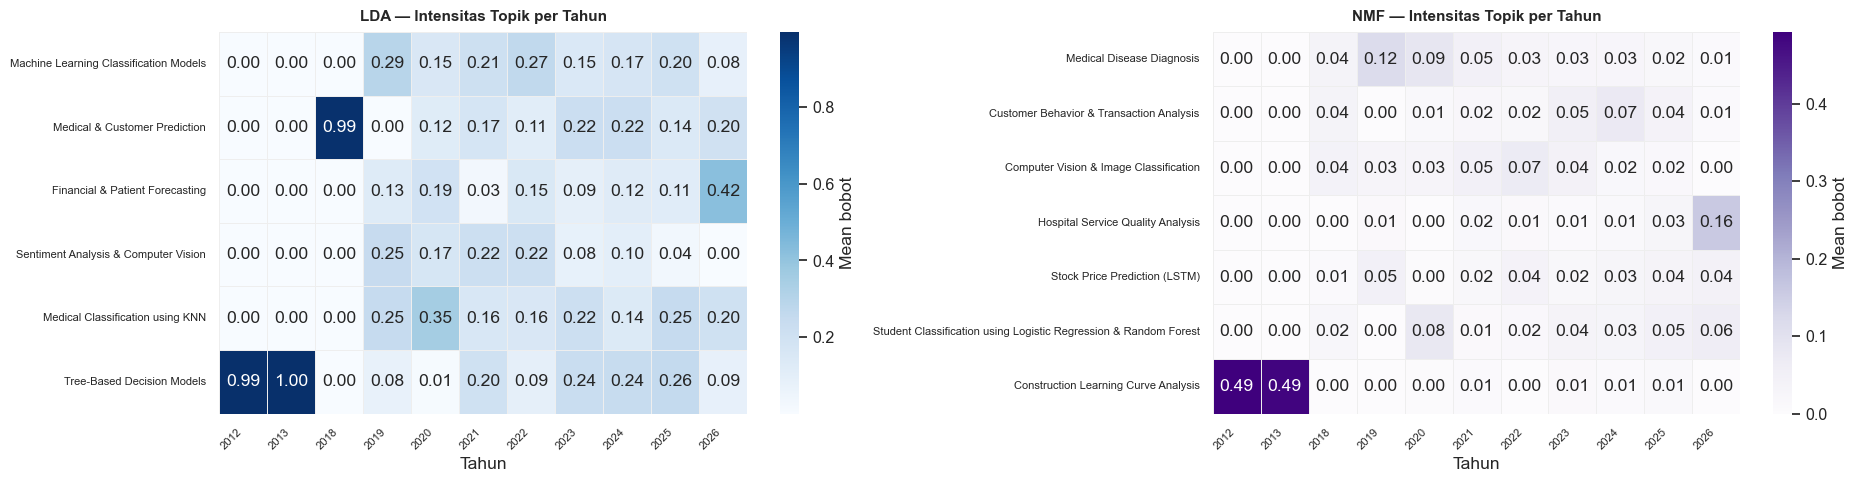

In [23]:
# ── 8.3 Heatmap: Tahun × Topik ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(19, 5))

for ax, evo, title, cmap in zip(
    axes,
    [lda_evo, nmf_evo],
    ['LDA — Intensitas Topik per Tahun', 'NMF — Intensitas Topik per Tahun'],
    ['Blues', 'Purples']
):
    sns.heatmap(
        evo.T.round(3), annot=True, fmt='.2f', cmap=cmap,
        linewidths=0.4, linecolor='#eee',
        cbar_kws={'label': 'Mean bobot'}, ax=ax
    )
    ax.set_title(title, fontsize=11, fontweight='bold', pad=8)
    ax.set_xlabel('Tahun'); ax.set_ylabel('')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', fontsize=8)
    plt.setp(ax.get_yticklabels(), fontsize=8)

plt.tight_layout()
plt.savefig('evolusi_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()


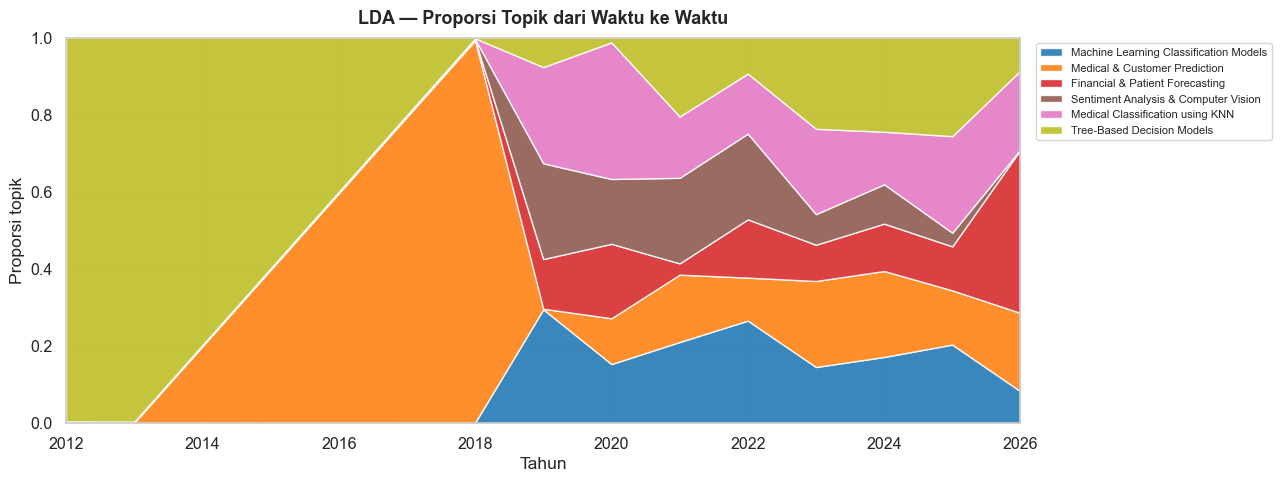

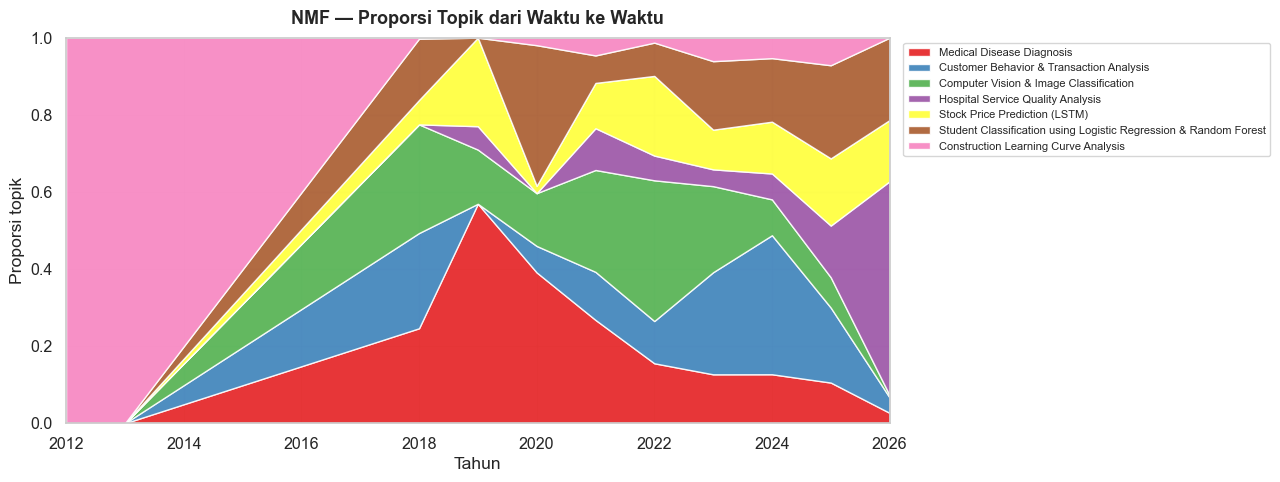

In [24]:
# ── 8.4 Stacked area chart (proporsi topik) ─────────────────────────────────
def stacked_area(evo, palette, title, filename, K):
    cols     = evo.columns.tolist()
    mat_pct  = evo.div(evo.sum(axis=1), axis=0).fillna(0)
    colors   = [palette(i/K) for i in range(K)]

    fig, ax  = plt.subplots(figsize=(13, 5))
    ax.stackplot(evo.index, mat_pct.T.values,
                 labels=cols, colors=colors, alpha=0.88)
    ax.set_title(title, fontsize=13, fontweight='bold', pad=10)
    ax.set_xlabel('Tahun'); ax.set_ylabel('Proporsi topik')
    ax.set_xlim(evo.index.min(), evo.index.max()); ax.set_ylim(0, 1)
    ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.show()

stacked_area(lda_evo, cm.tab10,
    'LDA — Proporsi Topik dari Waktu ke Waktu',
    'lda_stacked.png', K_LDA)

stacked_area(nmf_evo, cm.Set1,
    'NMF — Proporsi Topik dari Waktu ke Waktu',
    'nmf_stacked.png', K_NMF)


---
## Bagian 9 — Penyebaran Topik: Document-Topic Matrix & Pie Chart


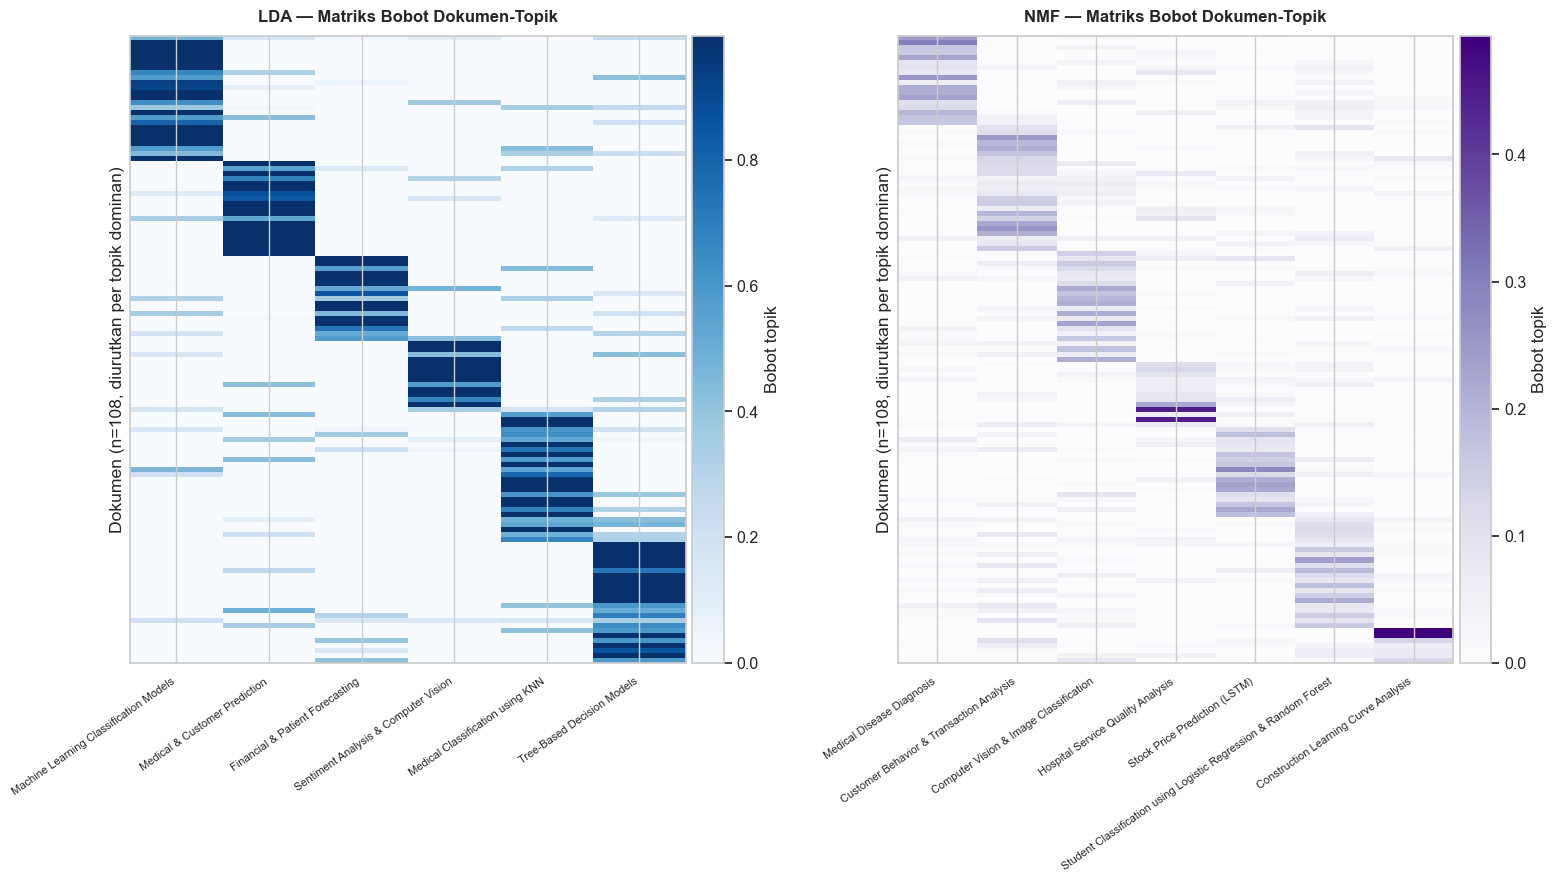

In [25]:
# ── 9.1 Document-Topic heatmap ──────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 9))

for ax, W, labels, cmap, title in zip(
    axes,
    [lda_W, nmf_W],
    [LDA_LABELS, NMF_LABELS],
    ['Blues', 'Purples'],
    ['LDA — Matriks Bobot Dokumen-Topik',
     'NMF — Matriks Bobot Dokumen-Topik']
):
    K = W.shape[1]
    sort_idx = W.argmax(axis=1).argsort()
    W_sorted = W[sort_idx]
    im = ax.imshow(W_sorted, aspect='auto', cmap=cmap, vmin=0)
    plt.colorbar(im, ax=ax, label='Bobot topik', pad=0.01)
    ax.set_xticks(range(K))
    ax.set_xticklabels([labels[i] for i in range(K)],
                       rotation=35, ha='right', fontsize=8)
    ax.set_yticks([])
    ax.set_ylabel(f'Dokumen (n=108, diurutkan per topik dominan)')
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
plt.savefig('doc_topic_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


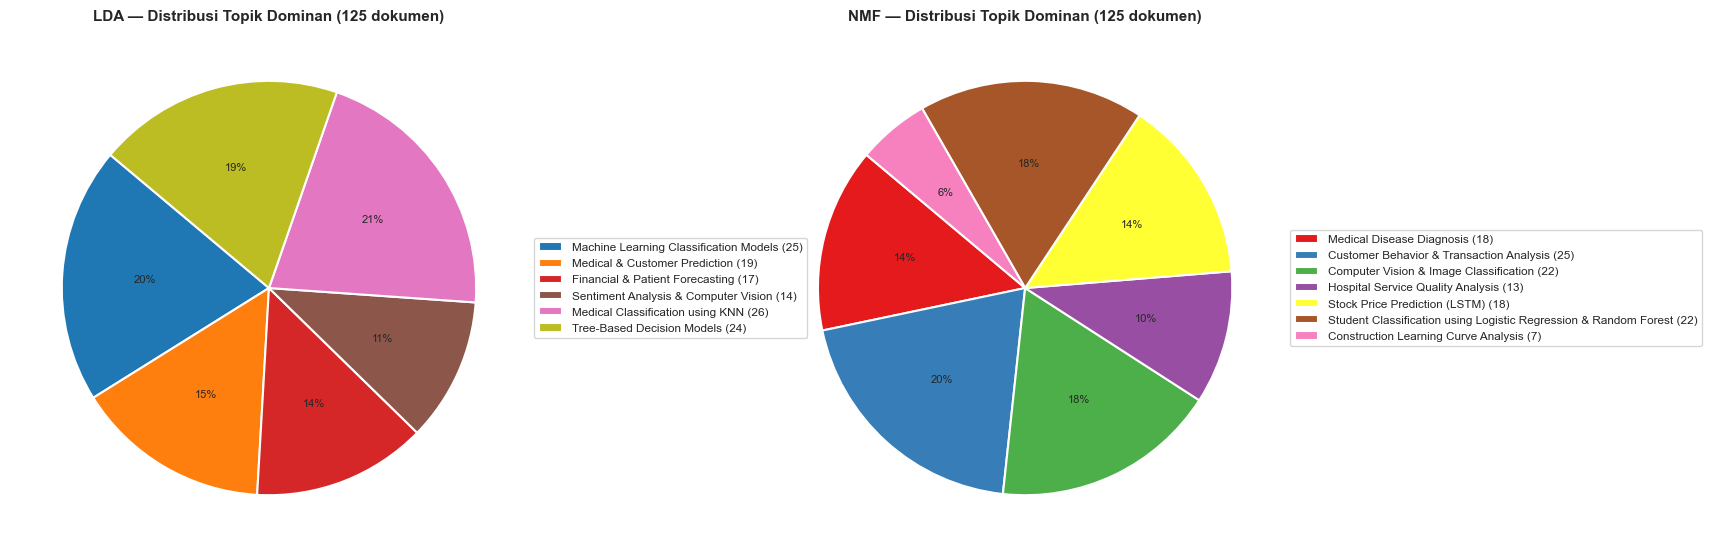

In [26]:
# ── 9.2 Pie chart distribusi topik dominan ──────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(17, 7))

for ax, col, labels, palette in zip(
    axes,
    ['lda_topic', 'nmf_topic'],
    [LDA_LABELS, NMF_LABELS],
    [cm.tab10, cm.Set1]
):
    counts  = df[col].value_counts().sort_index()
    lbls    = [f"{labels[i]} ({counts.get(i,0)})" for i in counts.index]
    colors  = [palette(i/len(counts)) for i in range(len(counts))]
    wedges, _, autotexts = ax.pie(
        counts.values, colors=colors,
        autopct='%1.0f%%', startangle=140,
        wedgeprops=dict(edgecolor='white', linewidth=1.5),
        textprops=dict(fontsize=8)
    )
    ax.legend(wedges, lbls, loc='center left',
              bbox_to_anchor=(1, 0, 0.5, 1), fontsize=8.5)
    model = 'LDA' if 'lda' in col else 'NMF'
    ax.set_title(f'{model} — Distribusi Topik Dominan (125 dokumen)',
                 fontweight='bold', fontsize=11)

plt.tight_layout()
plt.savefig('pie_distribusi.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Bagian 10 — Analisis Similaritas LDA vs NMF

Menggunakan **Jaccard Similarity** berdasarkan irisan 20 kata teratas:

$$J(i,j) = \frac{|\text{Top}_{20}(\text{LDA}_i) \cap \text{Top}_{20}(\text{NMF}_j)|}{|\text{Top}_{20}(\text{LDA}_i) \cup \text{Top}_{20}(\text{NMF}_j)|}$$

Topik dengan nilai J tinggi → teridentifikasi secara robust oleh **kedua** metode.


In [27]:
# ── 10.1 Hitung matriks Jaccard LDA × NMF ───────────────────────────────────
def top_word_set(H, vocab, n=20):
    return [set(vocab[H[i].argsort()[::-1][:n]]) for i in range(H.shape[0])]

lda_sets = top_word_set(lda_H, cv_vocab, n=20)
nmf_sets = top_word_set(nmf_H, tv_vocab, n=20)

sim_matrix = np.zeros((K_LDA, K_NMF))
for i, ls in enumerate(lda_sets):
    for j, ns in enumerate(nmf_sets):
        inter = len(ls & ns)
        union = len(ls | ns)
        sim_matrix[i, j] = inter / union if union > 0 else 0

print("Matriks Similaritas Jaccard (LDA baris × NMF kolom):")
sim_df = pd.DataFrame(
    sim_matrix.round(3),
    index  = [f'LDA-{i}: {LDA_LABELS[i][:20]}' for i in range(K_LDA)],
    columns= [f'NMF-{j}: {NMF_LABELS[j][:18]}' for j in range(K_NMF)]
)
print(sim_df.to_string())
print(f"\nPasangan paling mirip:")
max_idx = np.unravel_index(sim_matrix.argmax(), sim_matrix.shape)
print(f"  LDA Topik {max_idx[0]} ({LDA_LABELS[max_idx[0]]}) ↔ "
      f"NMF Topik {max_idx[1]} ({NMF_LABELS[max_idx[1]]}): "
      f"J = {sim_matrix[max_idx]:.3f}")


Matriks Similaritas Jaccard (LDA baris × NMF kolom):
                             NMF-0: Medical Disease Di  NMF-1: Customer Behavior   NMF-2: Computer Vision &   NMF-3: Hospital Service Q  NMF-4: Stock Price Predic  NMF-5: Student Classifica  NMF-6: Construction Learn
LDA-0: Machine Learning Cla                      0.053                      0.053                      0.111                      0.000                      0.053                      0.250                      0.000
LDA-1: Medical & Customer P                      0.081                      0.176                      0.111                      0.000                      0.026                      0.111                      0.000
LDA-2: Financial & Patient                       0.000                      0.053                      0.026                      0.111                      0.538                      0.000                      0.000
LDA-3: Sentiment Analysis &                      0.053                      0.0

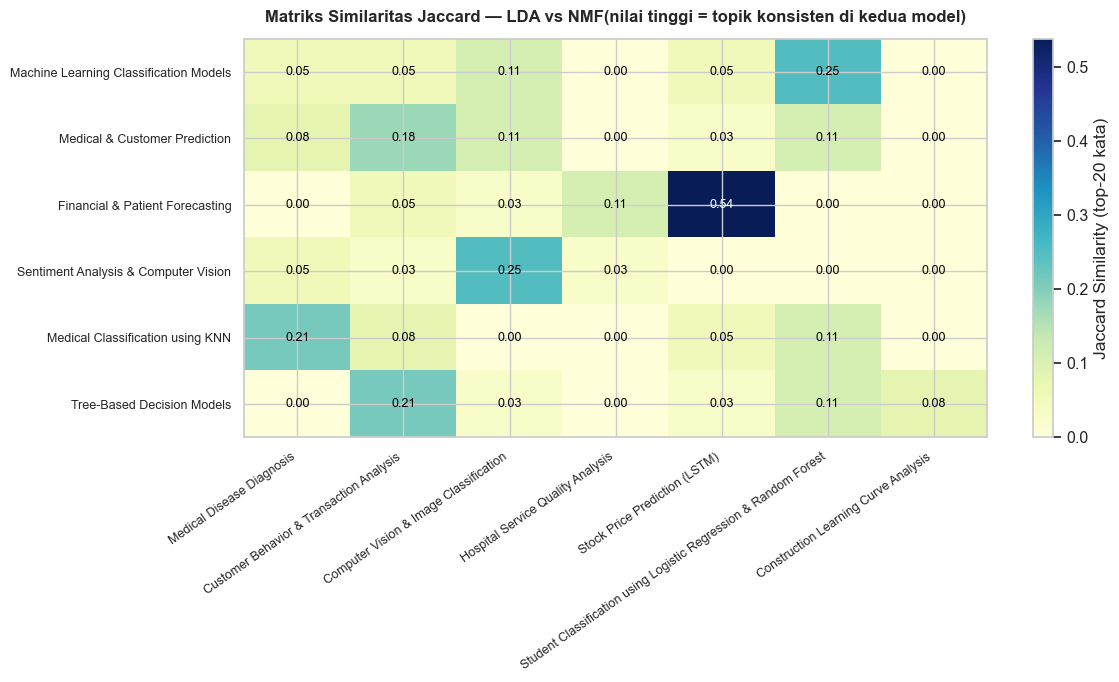

In [28]:
# ── 10.2 Visualisasi matriks similaritas ────────────────────────────────────
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(sim_matrix, cmap='YlGnBu', aspect='auto',
               vmin=0, vmax=sim_matrix.max())
plt.colorbar(im, ax=ax, label='Jaccard Similarity (top-20 kata)')

ax.set_xticks(range(K_NMF))
ax.set_xticklabels([NMF_LABELS[i] for i in range(K_NMF)],
                   rotation=35, ha='right', fontsize=9)
ax.set_yticks(range(K_LDA))
ax.set_yticklabels([LDA_LABELS[i] for i in range(K_LDA)], fontsize=9)

for i in range(K_LDA):
    for j in range(K_NMF):
        val = sim_matrix[i, j]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                fontsize=9, color='white' if val > 0.25 else 'black')

ax.set_title('Matriks Similaritas Jaccard — LDA vs NMF'
             '(nilai tinggi = topik konsisten di kedua model)',
             fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.savefig('similarity_matrix.png', dpi=150, bbox_inches='tight')
plt.show()


---
## Bagian 11 — Skor Rekomendasi Topik Penelitian

### Formula Skor Komposit (Bab III §3.10):

| Komponen | Formula | Makna |
|---|---|---|
| $S_{\text{coverage}}(k)$ | $|\{d: \text{dominant}(d)=k\}| / N$ | Proporsi dokumen dalam topik |
| $S_{\text{growth}}(k)$ | $\text{clip}(10 \times (\bar{w}_{k,\text{recent}} - \bar{w}_{k,\text{early}}) + 0.5,\; 0, 1)$ | Momentum pertumbuhan terkini |
| $S_{\text{recency}}(k)$ | $\max(\text{year}) / 2026$ | Kemutakhiran dokumen |
| $S_{\text{total}}(k)$ | $S_{\text{cov}} + S_{\text{growth}} + S_{\text{recency}}$ | **Skor akhir** (rentang 0–3) |

**Ambang batas prioritas:** ⭐ > 1.70 · ✅ 1.30–1.70 · ⚠ < 1.30


In [29]:

# ── 11.1 Hitung komponen skor rekomendasi ───────────────────────────────

# Membagi periode publikasi
early_years  = [y for y in years if y <= 2021]
recent_years = [y for y in years if y >= 2022]

# Rentang tahun publikasi seluruh dataset
valid_years = df['year_int'].dropna()

YEAR_MIN = int(valid_years.min())
YEAR_MAX = int(valid_years.max())

# Menghitung rata-rata bobot topik berdasarkan periode
def mean_w_years(W, df, target_years, K):
    mask = df['year_int'].isin(target_years).to_numpy()
    idx = np.flatnonzero(mask)

    return W[idx].mean(axis=0) if len(idx) > 0 else np.zeros(K)

early_w_nmf  = mean_w_years(nmf_W, df, early_years, K_NMF)
recent_w_nmf = mean_w_years(nmf_W, df, recent_years, K_NMF)

# Menghindari pembagian dengan nol
year_range = YEAR_MAX - YEAR_MIN

rec_rows = []

for k in range(K_NMF):

    # Posisi dokumen yang termasuk dalam topik ke-k
    idx_k = np.flatnonzero(
        (df['nmf_topic'] == k).to_numpy()
    )

    # 1. Coverage Score
    s_cov = len(idx_k) / len(df) if len(df) > 0 else 0

    # 2. Growth Score
    s_grow = float(np.clip(
        10 * (recent_w_nmf[k] - early_w_nmf[k]) + 0.5,
        0,
        1
    ))

    # 3. Recency Score (normalisasi min-max)
    if len(idx_k) > 0 and year_range > 0:
        latest_year = int(df.iloc[idx_k]['year_int'].max())

        s_rec = (
            (latest_year - YEAR_MIN) / year_range
        )
    else:
        latest_year = None
        s_rec = 0.0

    # 4. Total Score
    s_tot = s_cov + s_grow + s_rec

    # Kategori prioritas
    priority = (
        '⭐ Tinggi' if s_tot > 1.70
        else '✅ Sedang' if s_tot > 1.30
        else '⚠ Rendah'
    )

    rec_rows.append({
        'Topik'       : NMF_LABELS[k],
        'Dokumen'     : len(idx_k),
        'S_coverage'  : round(s_cov, 3),
        'S_growth'    : round(s_grow, 3),
        'Latest_Year' : latest_year,
        'S_recency'   : round(s_rec, 3),
        'S_total'     : round(s_tot, 3),
        'Prioritas'   : priority
    })

# Menyusun hasil berdasarkan skor total tertinggi
rec_df = pd.DataFrame(rec_rows).sort_values(
    'S_total',
    ascending=False
)

print(f"Rentang tahun dataset: {YEAR_MIN}–{YEAR_MAX}")
print("\nHasil Skor Rekomendasi Topik NMF:")
print(rec_df.to_string(index=False))



Rentang tahun dataset: 2012–2026

Hasil Skor Rekomendasi Topik NMF:
                                                           Topik  Dokumen  S_coverage  S_growth  Latest_Year  S_recency  S_total Prioritas
                        Customer Behavior & Transaction Analysis       25       0.200     0.784         2025      0.929    1.912  ⭐ Tinggi
Student Classification using Logistic Regression & Random Forest       22       0.176     0.682         2026      1.000    1.858  ⭐ Tinggi
                                   Stock Price Prediction (LSTM)       18       0.144     0.609         2026      1.000    1.753  ⭐ Tinggi
                               Hospital Service Quality Analysis       13       0.104     0.630         2026      1.000    1.734  ⭐ Tinggi
                          Computer Vision & Image Classification       22       0.176     0.456         2025      0.929    1.561  ✅ Sedang
                                       Medical Disease Diagnosis       18       0.144     0.136   

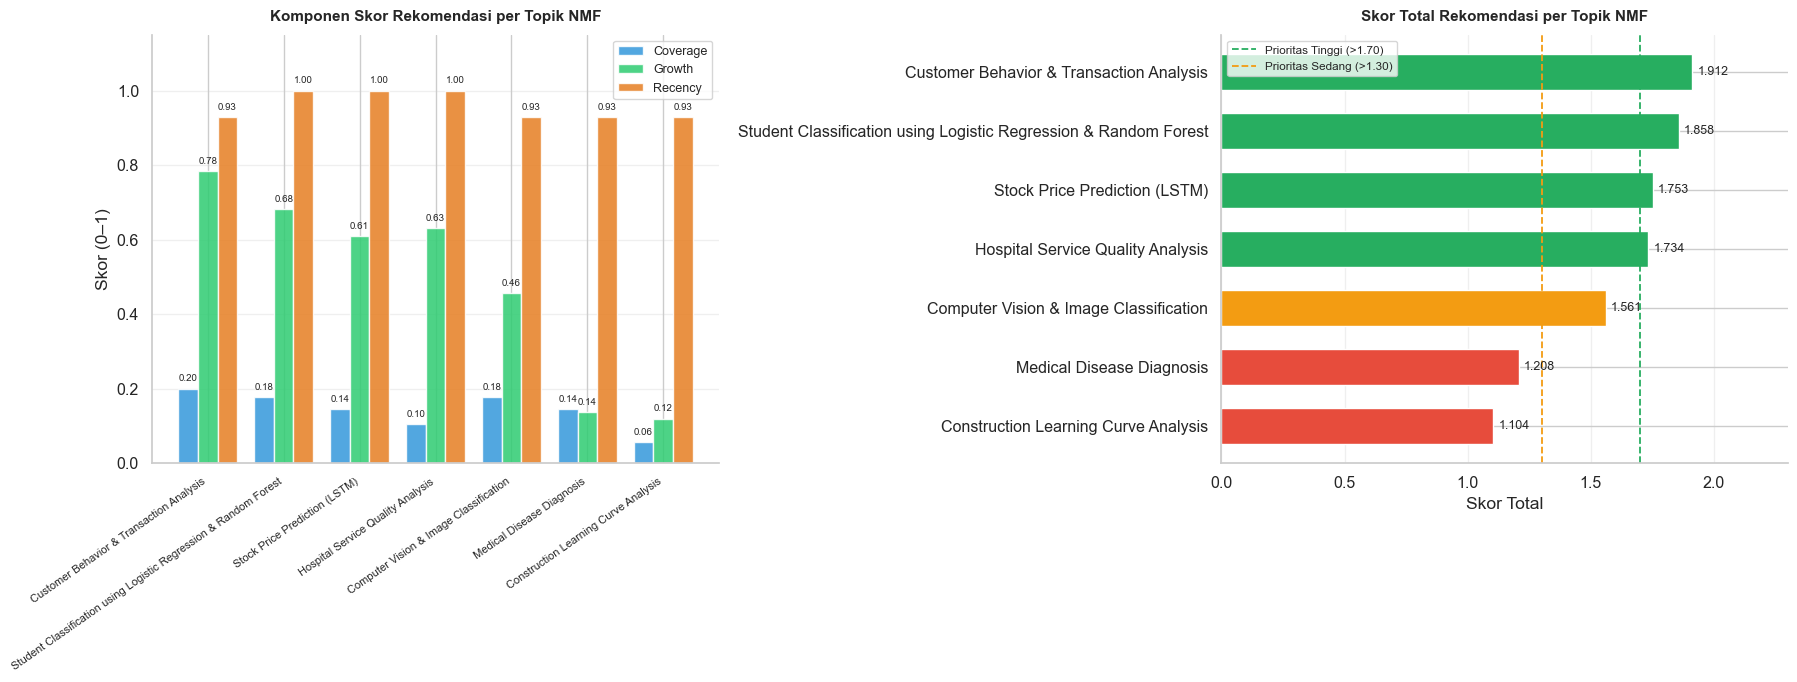

In [33]:

# ── 11.2 Bar chart skor rekomendasi ─────────────────────────────────────

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Grouped bar: 3 komponen skor per topik
ax = axes[0]
x = np.arange(len(rec_df))
w = 0.26

components = [
    ('S_coverage', 'Coverage', '#3498db'),
    ('S_growth', 'Growth', '#2ecc71'),
    ('S_recency', 'Recency', '#e67e22')
]

for offset, (col, label, color) in zip([-w, 0, w], components):
    bars = ax.bar(
        x + offset,
        rec_df[col],
        w,
        label=label,
        color=color,
        alpha=0.85,
        edgecolor='white'
    )

    for bar in bars:
        height = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.015,
            f'{height:.2f}',
            ha='center',
            va='bottom',
            fontsize=7
        )

ax.set_xticks(x)
ax.set_xticklabels(
    rec_df['Topik'],
    rotation=35,
    ha='right',
    fontsize=8
)
ax.set_title(
    'Komponen Skor Rekomendasi per Topik NMF',
    fontweight='bold',
    fontsize=11,
    pad=10
)
ax.set_ylabel('Skor (0–1)')
ax.set_ylim(0, 1.15)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

# Horizontal bar: skor total
ax = axes[1]

colors = [
    '#27ae60' if s > 1.70
    else '#f39c12' if s > 1.30
    else '#e74c3c'
    for s in rec_df['S_total']
]

bars = ax.barh(
    rec_df['Topik'][::-1],
    rec_df['S_total'][::-1],
    color=colors[::-1],
    edgecolor='white',
    height=0.6
)

ax.axvline(
    1.70, color='#27ae60', ls='--',
    lw=1.3, label='Prioritas Tinggi (>1.70)'
)
ax.axvline(
    1.30, color='#f39c12', ls='--',
    lw=1.3, label='Prioritas Sedang (>1.30)'
)

for bar, val in zip(bars, rec_df['S_total'][::-1]):
    ax.text(
        bar.get_width() + 0.02,
        bar.get_y() + bar.get_height()/2,
        f'{val:.3f}',
        va='center',
        fontsize=9
    )

ax.set_title(
    'Skor Total Rekomendasi per Topik NMF',
    fontweight='bold',
    fontsize=11,
    pad=10
)
ax.set_xlabel('Skor Total')
ax.set_xlim(0, max(2.3, rec_df['S_total'].max() + 0.25))
ax.legend(fontsize=8.5)
ax.grid(axis='x', alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.savefig(
    'rekomendasi_skor.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()



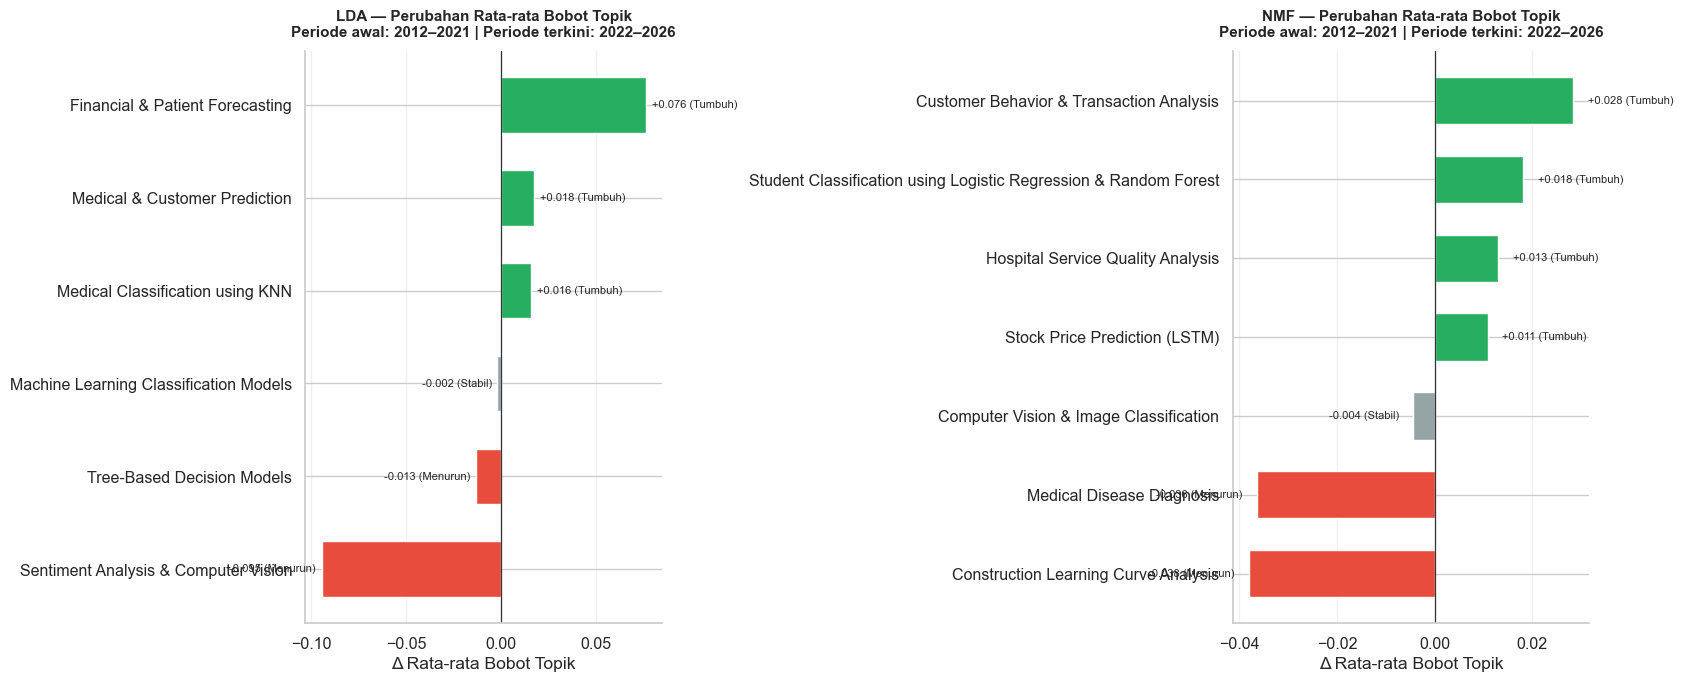

In [34]:

# ── 11.3 Tren topik tumbuh vs menurun ───────────────────────────────────

# Menghitung rata-rata bobot topik LDA berdasarkan periode
early_lda = mean_w_years(
    lda_W, df, early_years, K_LDA
)

recent_lda = mean_w_years(
    lda_W, df, recent_years, K_LDA
)

# Menghitung perubahan rata-rata bobot topik
delta_lda = recent_lda - early_lda
delta_nmf = recent_w_nmf - early_w_nmf

# Ambang klasifikasi tren
THRESHOLD = 0.005

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

trend_data = [
    (delta_lda, LDA_LABELS, 'LDA'),
    (delta_nmf, NMF_LABELS, 'NMF')
]

for ax, (delta, labels, tag) in zip(axes, trend_data):

    order = np.argsort(delta)

    colors = [
        '#27ae60' if delta[i] > THRESHOLD
        else '#e74c3c' if delta[i] < -THRESHOLD
        else '#95a5a6'
        for i in order
    ]

    bars = ax.barh(
        [labels[i] for i in order],
        delta[order],
        color=colors,
        edgecolor='white',
        height=0.6
    )

    ax.axvline(0, color='#333333', lw=0.9)

    # Label nilai dan kategori tren
    for bar, val in zip(bars, delta[order]):

        if val > THRESHOLD:
            trend = 'Tumbuh'
        elif val < -THRESHOLD:
            trend = 'Menurun'
        else:
            trend = 'Stabil'

        xpos = (
            bar.get_width() + 0.003
            if val >= 0
            else bar.get_width() - 0.003
        )

        ha = 'left' if val >= 0 else 'right'

        ax.text(
            xpos,
            bar.get_y() + bar.get_height() / 2,
            f'{val:+.3f} ({trend})',
            va='center',
            ha=ha,
            fontsize=8
        )

    ax.set_title(
        f'{tag} — Perubahan Rata-rata Bobot Topik\n'
        f'Periode awal: {min(early_years)}–{max(early_years)} | '
        f'Periode terkini: {min(recent_years)}–{max(recent_years)}',
        fontsize=11,
        fontweight='bold',
        pad=10
    )

    ax.set_xlabel('Δ Rata-rata Bobot Topik')
    ax.grid(axis='x', alpha=0.3)
    ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()

plt.savefig(
    'tren_pertumbuhan.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()



---
## Bagian 12 — Ekspor Hasil

Menyimpan seluruh hasil analisis ke dalam:
1. **`hasil_topic_modeling.xlsx`** — 4 sheet: Papers, LDA Topics, NMF Topics, Rekomendasi
2. **Semua gambar `.png`** sudah tersimpan di folder yang sama


In [32]:
# ── 12.1 Sheet 1: Annotated papers ─────────────────────────────────────────
out = df[['title_clean','authors','year_int','kw_list',
          'lda_topic','lda_label','lda_weight',
          'nmf_topic','nmf_label','nmf_weight']].copy()
out['kw_list'] = out['kw_list'].apply(
    lambda x: '; '.join(x) if isinstance(x, list) else x
)
out.columns = ['Judul', 'Penulis', 'Tahun', 'Kata Kunci',
               'ID Topik LDA', 'Label Topik LDA', 'Bobot LDA',
               'ID Topik NMF', 'Label Topik NMF', 'Bobot NMF']

# ── 12.2 Sheet 2: LDA top words ─────────────────────────────────────────────
lda_tbl = pd.DataFrame([{
    'ID Topik': k,
    'Nama Topik': LDA_LABELS[k],
    'Top-15 Kata': ', '.join(get_top_words(lda_H, cv_vocab, n=15)[k]),
    'Jumlah Dokumen': (df['lda_topic'] == k).sum()
} for k in range(K_LDA)])

# ── 12.3 Sheet 3: NMF top words ─────────────────────────────────────────────
nmf_tbl = pd.DataFrame([{
    'ID Topik': k,
    'Nama Topik': NMF_LABELS[k],
    'Top-15 Kata': ', '.join(get_top_words(nmf_H, tv_vocab, n=15)[k]),
    'Jumlah Dokumen': (df['nmf_topic'] == k).sum()
} for k in range(K_NMF)])

# ── 12.4 Sheet 4: Skor rekomendasi ──────────────────────────────────────────
rec_export = rec_df.copy()

# ── 12.5 Tulis ke Excel ─────────────────────────────────────────────────────
fname = 'hasil_topic_modeling.xlsx'
with pd.ExcelWriter(fname, engine='openpyxl') as writer:
    out.to_excel(writer,         sheet_name='Papers',         index=False)
    lda_tbl.to_excel(writer,     sheet_name='LDA Topics',     index=False)
    nmf_tbl.to_excel(writer,     sheet_name='NMF Topics',     index=False)
    rec_export.to_excel(writer,  sheet_name='Rekomendasi',    index=False)
    sim_df.to_excel(writer,      sheet_name='Similaritas',)

print(f"✅ Hasil disimpan ke: {fname}")
print(f"   Sheet 1 — Papers        : {len(out)} baris")
print(f"   Sheet 2 — LDA Topics    : {len(lda_tbl)} topik")
print(f"   Sheet 3 — NMF Topics    : {len(nmf_tbl)} topik")
print(f"   Sheet 4 — Rekomendasi   : {len(rec_export)} topik")
print(f"   Sheet 5 — Similaritas   : {sim_df.shape}")


PermissionError: [Errno 13] Permission denied: 'hasil_topic_modeling.xlsx'

In [ ]:
# ── 12.6 Ringkasan akhir ────────────────────────────────────────────────────
print("=" * 65)
print("RINGKASAN ANALISIS TOPIC MODELING")
print("=" * 65)
print(f"Dataset  : 125 metadata penelitian ML, FAIDAS UPH (2012–2026)")
print(f"LDA      : K=6, Batch EM, α=0.10, η=0.01")
print(f"           Perplexity final = {lda.perplexity(dtm_count):.2f}")
print(f"NMF      : K=7, Multiplicative Update, init=random")
print(f"           Reconstruction Error = {nmf.reconstruction_err_:.4f}")
print()
print("TOPIK LDA TERIDENTIFIKASI:")
for k, v in LDA_LABELS.items():
    n = (df['lda_topic'] == k).sum()
    print(f"  Topik {k} ({n:>3} dok): {v}")
print()
print("TOPIK NMF TERIDENTIFIKASI:")
for k, v in NMF_LABELS.items():
    n = (df['nmf_topic'] == k).sum()
    print(f"  Topik {k} ({n:>3} dok): {v}")
print()
print("TOP REKOMENDASI TOPIK PENELITIAN (berdasarkan S_total):")
for _, row in rec_df.head(4).iterrows():
    print(f"  {row['Prioritas']}  {row['Topik']:<38} S={row['S_total']:.3f}")
print()
print("OUTPUT FILES YANG DIHASILKAN:")
outputs = [
    'eda_distribusi_tahun.png', 'eda_token_stats.png', 'dtm_visualisasi.png',
    'k_selection_diagnostics.png', 'distribusi_topik.png',
    'lda_topwords.png', 'nmf_topwords.png',
    'evolusi_topik_line.png', 'evolusi_heatmap.png',
    'lda_stacked.png', 'nmf_stacked.png',
    'doc_topic_matrix.png', 'pie_distribusi.png',
    'similarity_matrix.png', 'rekomendasi_skor.png',
    'tren_pertumbuhan.png', 'hasil_topic_modeling.xlsx'
]
for f in outputs:
    print(f"  📄 {f}")
print("=" * 65)
